# Pruebas por etapa — estructuras propias vs. Python

Pruebas de correctitud, tiempos y memoria de las estructuras de cada etapa, comparadas con la
implementación de Python o la alternativa exacta/simple cuando aplica.

**Regla:** este notebook solo importa los módulos de etapa (`pipeline_eda.etapaN_*`) y `evento`;
nunca el orquestador. Cada sección se puede correr sola después de las dos celdas de setup.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Busca hacia arriba la carpeta que contiene pipeline_eda/, sin depender del cwd del kernel.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline_eda").is_dir())
sys.path.insert(0, str(RAIZ))
CSV_REAL = RAIZ / "data" / "2019-Oct-10M.csv"

## Herramientas de medición

- `medir(fn, reps)`: promedio y desviación estándar de `reps` ejecuciones.
- `memoria_pico(fn)`: memoria pico que reserva `fn()`, con `tracemalloc` (lo que existía antes no cuenta).
- `graficar_loglog(resultados, ...)`: escalabilidad log-log con pendientes de referencia.

In [2]:
import bisect
import math
import platform
import random
import statistics
import time
import tracemalloc
from collections import deque
from itertools import islice

import matplotlib.pyplot as plt

SEED = 42
print(platform.platform(), "| Python", platform.python_version(), "| seed", SEED)


def medir(fn, reps):
    """Ejecuta fn() `reps` veces; devuelve (promedio, desviación estándar) en segundos."""
    tiempos = []
    for _ in range(reps):
        inicio = time.perf_counter()
        fn()
        tiempos.append(time.perf_counter() - inicio)
    return statistics.mean(tiempos), (statistics.stdev(tiempos) if reps > 1 else 0.0)


def memoria_pico(fn):
    """Memoria pico (bytes) reservada durante fn()."""
    tracemalloc.start()
    try:
        fn()
        return tracemalloc.get_traced_memory()[1]
    finally:
        tracemalloc.stop()


REFERENCIAS = {"log n": math.log2, "n": lambda n: n, "n log n": lambda n: n * math.log2(n)}


def graficar_loglog(resultados, titulo, referencias=(), unidad="s"):
    """resultados: {nombre: {n: valor}}. Las referencias se anclan al primer punto de la primera serie."""
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for nombre, serie in resultados.items():
        ns = sorted(serie)
        ax.loglog(ns, [serie[n] for n in ns], "o-", label=nombre)
    base = next(iter(resultados.values()))
    ns = sorted(base)
    for estilo, ref in zip((":", "--", "-."), referencias):
        f = REFERENCIAS[ref]
        ax.loglog(ns, [base[ns[0]] * f(n) / f(ns[0]) for n in ns], estilo, color="gray", label=f"O({ref})")
    ax.set_xlabel("n")
    ax.set_ylabel(unidad)
    ax.set_title(titulo)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    plt.show()

macOS-27.2-arm64-arm-64bit-Mach-O | Python 3.14.4 | seed 42


## Etapa 0 — Ingesta y buffer: `leer_csv`, `ColaFIFO` e `Ingesta`

### 0.1 Correctitud de `ColaFIFO`
Operaciones al azar contra `collections.deque`, con y sin capacidad.

In [3]:
from pipeline_eda.etapa0_ingesta import ColaFIFO, Ingesta, leer_csv

rng = random.Random(SEED)
for capacidad in (None, 1, 7, 100):
    cola, ref = ColaFIFO(capacidad), deque()
    for _ in range(20_000):
        op = rng.random()
        if op < 0.5:
            x = rng.random()
            entro = cola.encolar(x)
            assert entro == (capacidad is None or len(ref) < capacidad)  # False = backpressure
            if entro:
                ref.append(x)
        elif op < 0.8:
            if ref:
                assert cola.desencolar() == ref.popleft()
            else:
                try:
                    cola.desencolar()
                    raise AssertionError("debió lanzar IndexError")
                except IndexError:
                    pass
        else:
            k = rng.randint(0, 10)
            assert cola.desencolar_lote(k) == [ref.popleft() for _ in range(min(k, len(ref)))]
        assert len(cola) == len(ref)
print("ColaFIFO == deque (encolar, desencolar, desencolar_lote y capacidad)")

ColaFIFO == deque (encolar, desencolar, desencolar_lote y capacidad)


### 0.2 `Ingesta`: lotes y backpressure
El orden se conserva y los lotes tienen `tam_lote` eventos. Si la capacidad es menor que el lote, el
productor encuentra el buffer lleno (bloqueo) y se entrega lo acumulado.

In [4]:
for capacidad, tam_lote in ((50_000, 10), (3, 10), (None, 4), (10, 10)):
    ing = Ingesta(capacidad, tam_lote, sintetizar=False)  # solo el buffer
    lotes_e0 = list(ing.lotes(range(103)))
    assert [x for lote in lotes_e0 for x in lote] == list(range(103))
    tam = min(tam_lote, capacidad) if capacidad else tam_lote
    assert all(len(lote) == tam for lote in lotes_e0[:-1]) and 0 < len(lotes_e0[-1]) <= tam
    m = ing.metricas()
    print(f"capacidad={capacidad!s:>6} tam_lote={tam_lote:>3}  lotes={m['lotes']:>3}  "
          f"ocupación máx={m['ocupacion_max']:>3}  bloqueos={m['bloqueos']}")

capacidad= 50000 tam_lote= 10  lotes= 11  ocupación máx= 10  bloqueos=0
capacidad=     3 tam_lote= 10  lotes= 35  ocupación máx=  3  bloqueos=34
capacidad=  None tam_lote=  4  lotes= 26  ocupación máx=  4  bloqueos=0
capacidad=    10 tam_lote= 10  lotes= 11  ocupación máx= 10  bloqueos=0


### 0.3 `leer_csv` con datos reales
Tipos del contrato (`datetime` en UTC, int, float, `None`) y throughput de la etapa (lectura + buffer) sobre 1M de filas.

In [5]:
from datetime import datetime

primeros = list(leer_csv(CSV_REAL, limite=3))
for ev in primeros:
    print(ev)
assert all(isinstance(ev.event_time, datetime) and ev.event_time.tzinfo is not None and isinstance(ev.price, float) for ev in primeros)


def ingerir(n):
    ing = Ingesta(capacidad=50_000, tam_lote=10_000)
    for _ in ing.lotes(leer_csv(CSV_REAL, limite=n)):
        pass
    return ing


N_E0 = 1_000_000
prom, desv = medir(lambda: ingerir(N_E0), 3)
print(f"{N_E0:,} filas: {prom:.2f} s ± {desv:.2f}  ({N_E0 / prom:,.0f} eventos/s)")
ingerir(N_E0).metricas()

Event(event_time=datetime.datetime(2019, 10, 1, 0, 0, tzinfo=datetime.timezone.utc), event_type='view', product_id=44600062, category_id=2103807459595387724, category_code=None, brand='shiseido', price=35.79, user_id=541312140, user_session='72d76fde-8bb3-4e00-8c23-a032dfed738c', order_id=None, tipo_envio=None, card_id=None, is_fraud=False, is_dup=False)
Event(event_time=datetime.datetime(2019, 10, 1, 0, 0, tzinfo=datetime.timezone.utc), event_type='view', product_id=3900821, category_id=2053013552326770905, category_code='appliances.environment.water_heater', brand='aqua', price=33.2, user_id=554748717, user_session='9333dfbd-b87a-4708-9857-6336556b0fcc', order_id=None, tipo_envio=None, card_id=None, is_fraud=False, is_dup=False)
Event(event_time=datetime.datetime(2019, 10, 1, 0, 0, 1, tzinfo=datetime.timezone.utc), event_type='view', product_id=17200506, category_id=2053013559792632471, category_code='furniture.living_room.sofa', brand=None, price=543.1, user_id=519107250, user_sessi

1,000,000 filas: 3.44 s ± 0.12  (291,032 eventos/s)


{'ingeridos': 1020620,
 'lotes': 103,
 'ocupacion_max': 10000,
 'bloqueos': 0,
 'sintetico': {'duplicados_reales': 502,
  'duplicados_inyectados': 20240,
  'rafagas_fraude': 38,
  'intentos_fraude': 380,
  'tarjetas_senaladas': 50}}

### 0.4 Componente sintético
Determinista con `SEMILLA`; `order_id` = sesión y un solo `tipo_envio` por orden; las ráfagas usan
tarjetas robadas (solo una parte señalada). Se compara la etapa 1 contra `is_dup`.

In [6]:
from collections import Counter

from pipeline_eda.etapa0_ingesta import Sintetizador
from pipeline_eda.etapa1_preproceso import Preprocesador

N_SINT = 1_000_000
firma = lambda e: (e.event_time, e.event_type, e.product_id, e.user_id, e.card_id, e.tipo_envio, e.is_dup, e.is_fraud)
sint = Sintetizador()
stream = list(sint.flujo(leer_csv(CSV_REAL, limite=N_SINT)))
assert [firma(e) for e in stream] == [firma(e) for e in Sintetizador().flujo(leer_csv(CSV_REAL, limite=N_SINT))]

compras = [e for e in stream if e.event_type == "purchase" and not e.is_fraud]
envio_por_orden = {}
for e in compras:
    assert e.order_id == e.user_session and e.card_id is not None
    assert envio_por_orden.setdefault(e.order_id, e.tipo_envio) == e.tipo_envio
fraude = [e for e in stream if e.is_fraud]
assert all(e.card_id in sint.tarjetas_robadas for e in fraude)
print(f"{len(stream):,} eventos de {N_SINT:,} reales", sint.metricas())
print("tipo de envío por orden:", dict(Counter(envio_por_orden.values())))
print(f"intentos de fraude: {len(fraude)}, con tarjeta señalada: {sum(e.card_id in sint.senaladas for e in fraude)}")

# Etapa 1 contra la verdad de referencia
e0, e1 = Ingesta(50_000, 10_000), Preprocesador(100_000)
emitidos = [ev for lote in e0.lotes(leer_csv(CSV_REAL, limite=N_SINT)) for ev in e1.procesar(lote)]
m = e1.metricas()
print(f"is_dup en el stream: {sum(e.is_dup for e in stream):,} | descartados por la etapa 1: "
      f"{m['duplicados_lote'] + m['duplicados_ventana']:,} | is_dup que pasaron (más lejos que la ventana): "
      f"{sum(e.is_dup for e in emitidos)}")

1,020,620 eventos de 1,000,000 reales {'duplicados_reales': 502, 'duplicados_inyectados': 20240, 'rafagas_fraude': 38, 'intentos_fraude': 380, 'tarjetas_senaladas': 50}
tipo de envío por orden: {'estandar': 8601, 'express': 2840, 'programada': 2875}
intentos de fraude: 380, con tarjeta señalada: 200


is_dup en el stream: 20,742 | descartados por la etapa 1: 20,619 | is_dup que pasaron (más lejos que la ventana): 87


### 0.5 `ColaFIFO` vs `deque` vs `list.pop(0)`
Encolar n elementos y luego desencolarlos todos. `list.pop(0)` corre los n−1 elementos restantes en
cada llamada (O(n²) en total), así que solo se mide hasta 100K.

n=    1,000  ColaFIFO       0.00023 s ± 0.00001  (100 reps)
n=    1,000  deque          0.00005 s ± 0.00001  (100 reps)
n=    1,000  list.pop(0)    0.00011 s ± 0.00002  (100 reps)


n=   10,000  ColaFIFO       0.00480 s ± 0.01828  (100 reps)
n=   10,000  deque          0.00053 s ± 0.00004  (100 reps)


n=   10,000  list.pop(0)    0.00622 s ± 0.00012  (100 reps)
n=  100,000  ColaFIFO       0.02343 s ± 0.00025  (5 reps)
n=  100,000  deque          0.00528 s ± 0.00004  (5 reps)


n=  100,000  list.pop(0)    0.80036 s ± 0.02600  (5 reps)


n=1,000,000  ColaFIFO       0.36410 s ± 0.08997  (3 reps)
n=1,000,000  deque          0.05384 s ± 0.00118  (3 reps)


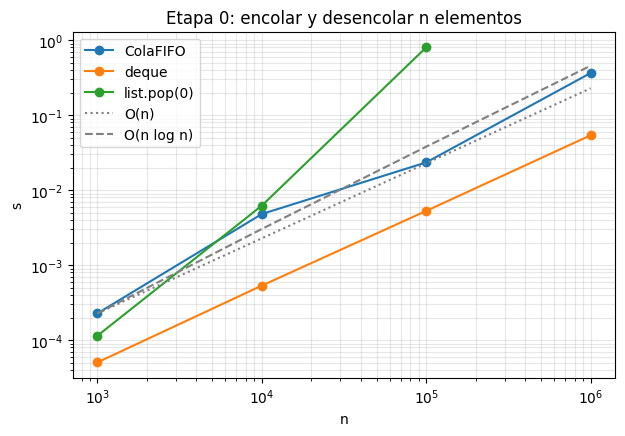

In [7]:
TAMANOS_E0 = [1_000, 10_000, 100_000, 1_000_000]
REPS_E0 = {1_000: 100, 10_000: 100, 100_000: 5, 1_000_000: 3}


def con_cola_fifo(n):
    cola = ColaFIFO()
    for i in range(n):
        cola.encolar(i)
    for _ in range(n):
        cola.desencolar()


def con_deque(n):
    cola = deque()
    for i in range(n):
        cola.append(i)
    for _ in range(n):
        cola.popleft()


def con_lista(n):
    cola = []
    for i in range(n):
        cola.append(i)
    for _ in range(n):
        cola.pop(0)


casos_e0 = {"ColaFIFO": con_cola_fifo, "deque": con_deque, "list.pop(0)": con_lista}
tiempos_cola = {}
for n in TAMANOS_E0:
    for nombre, fn in casos_e0.items():
        if nombre == "list.pop(0)" and n > 100_000:
            continue
        prom, desv = medir(lambda: fn(n), REPS_E0[n])
        tiempos_cola.setdefault(nombre, {})[n] = prom
        print(f"n={n:>9,}  {nombre:12} {prom:9.5f} s ± {desv:.5f}  ({REPS_E0[n]} reps)")

graficar_loglog(tiempos_cola, "Etapa 0: encolar y desencolar n elementos", referencias=("n", "n log n"))

In [8]:
# Memoria pico al tener n elementos encolados a la vez
def llenar(clase, n):
    def fn():
        cola = clase()
        agregar = cola.encolar if isinstance(cola, ColaFIFO) else cola.append
        for i in range(n):
            agregar(i)
    return fn


for n in (100_000, 1_000_000):
    for nombre, clase in (("ColaFIFO", ColaFIFO), ("deque", deque), ("list", list)):
        print(f"n={n:>9,}  {nombre:9} pico {memoria_pico(llenar(clase, n)) / 1e6:7.2f} MB")

n=  100,000  ColaFIFO  pico    7.99 MB
n=  100,000  deque     pico    4.02 MB
n=  100,000  list      pico    3.99 MB


n=1,000,000  ColaFIFO  pico   79.99 MB


n=1,000,000  deque     pico   40.24 MB


n=1,000,000  list      pico   40.44 MB


## Etapa 1 — Preprocesamiento: merge sort, búsqueda binaria y deduplicación

### 1.1 Correctitud
`merge_sort` contra `sorted()` (incluida la estabilidad: las tuplas llevan el índice de llegada) y
`busqueda_binaria` contra `bisect.bisect_left`.

In [9]:
from pipeline_eda.etapa1_preproceso import Preprocesador, busqueda_binaria, merge_sort

rng = random.Random(SEED)

for _ in range(2_000):
    n = rng.randint(0, 60)
    xs = [(rng.randint(0, 8), i) for i in range(n)]  # claves repetidas; el índice deja ver la estabilidad
    forma = rng.choice(["azar", "ordenada", "invertida", "casi"])
    if forma == "ordenada":
        xs.sort()
    elif forma == "invertida":
        xs.sort(reverse=True)
    elif forma == "casi" and n > 1:
        xs.sort()
        for _ in range(2):
            a, b = rng.randrange(n), rng.randrange(n)
            xs[a], xs[b] = xs[b], xs[a]
    assert merge_sort(xs, lambda t: t[0]) == sorted(xs, key=lambda t: t[0]), (forma, xs)

for _ in range(2_000):
    a = sorted(rng.randint(0, 30) for _ in range(rng.randint(0, 40)))
    for objetivo in range(-2, 33):
        i = bisect.bisect_left(a, objetivo)
        assert busqueda_binaria(a, objetivo) == (i if i < len(a) and a[i] == objetivo else -1)

print("merge_sort == sorted() (estable) y busqueda_binaria == bisect en todos los casos")

merge_sort == sorted() (estable) y busqueda_binaria == bisect en todos los casos


### 1.2 Tiempo: `merge_sort` vs `sorted()`
Entrada al azar (se espera O(n log n)) y ya ordenada (O(n): un solo tramo, como los lotes que llegan
ordenados por tiempo). Ambos reciben una función `clave` para que la comparación sea justa.
Se usan 100 repeticiones donde es viable y menos en los tamaños grandes.

In [10]:
TAMANOS_E1 = [1_000, 10_000, 100_000, 1_000_000]
REPS_E1 = {1_000: 100, 10_000: 100, 100_000: 20, 1_000_000: 3}
identidad = lambda x: x

tiempos_orden = {}
for forma in ("azar", "ordenada"):
    for n in TAMANOS_E1:
        xs = [rng.random() for _ in range(n)]
        if forma == "ordenada":
            xs.sort()
        for nombre, fn in (("merge_sort", lambda: merge_sort(xs, identidad)),
                           ("sorted", lambda: sorted(xs, key=identidad))):
            prom, desv = medir(fn, REPS_E1[n])
            tiempos_orden.setdefault(f"{nombre} ({forma})", {})[n] = prom
            print(f"{forma:9} n={n:>9,}  {nombre:10} {prom:10.5f} s ± {desv:.5f}  ({REPS_E1[n]} reps)")

azar      n=    1,000  merge_sort    0.00083 s ± 0.00001  (100 reps)
azar      n=    1,000  sorted        0.00008 s ± 0.00001  (100 reps)


azar      n=   10,000  merge_sort    0.01125 s ± 0.00026  (100 reps)
azar      n=   10,000  sorted        0.00121 s ± 0.00004  (100 reps)


azar      n=  100,000  merge_sort    0.16087 s ± 0.00889  (20 reps)


azar      n=  100,000  sorted        0.01593 s ± 0.00043  (20 reps)


azar      n=1,000,000  merge_sort    2.86772 s ± 0.06708  (3 reps)


azar      n=1,000,000  sorted        0.21127 s ± 0.00168  (3 reps)
ordenada  n=    1,000  merge_sort    0.00009 s ± 0.00002  (100 reps)
ordenada  n=    1,000  sorted        0.00003 s ± 0.00000  (100 reps)
ordenada  n=   10,000  merge_sort    0.00091 s ± 0.00005  (100 reps)
ordenada  n=   10,000  sorted        0.00031 s ± 0.00001  (100 reps)


ordenada  n=  100,000  merge_sort    0.01179 s ± 0.00104  (20 reps)
ordenada  n=  100,000  sorted        0.00369 s ± 0.00050  (20 reps)


ordenada  n=1,000,000  merge_sort    0.25512 s ± 0.00818  (3 reps)


ordenada  n=1,000,000  sorted        0.14754 s ± 0.00317  (3 reps)


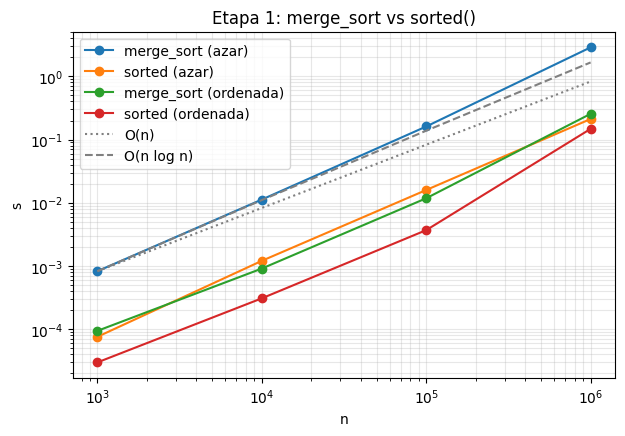

In [11]:
graficar_loglog(tiempos_orden, "Etapa 1: merge_sort vs sorted()", referencias=("n", "n log n"))

### 1.3 Memoria pico: `merge_sort` vs `sorted()`
`merge_sort` reserva la lista de claves y dos buffers de índices: O(n) extra.

In [12]:
for n in (10_000, 100_000, 1_000_000):
    xs = [rng.random() for _ in range(n)]
    for nombre, fn in (("merge_sort", lambda: merge_sort(xs, identidad)),
                       ("sorted", lambda: sorted(xs, key=identidad))):
        print(f"n={n:>9,}  {nombre:10} pico {memoria_pico(fn) / 1e6:8.2f} MB")

n=   10,000  merge_sort pico     0.77 MB
n=   10,000  sorted     pico     0.24 MB


n=  100,000  merge_sort pico     7.85 MB
n=  100,000  sorted     pico     2.40 MB


n=1,000,000  merge_sort pico    78.66 MB


n=1,000,000  sorted     pico    24.00 MB


### 1.4 Búsqueda: `busqueda_binaria` vs `bisect` vs `in set`
Tiempo por consulta. `bisect` es la misma búsqueda binaria hecha en C; `set` es hash, O(1) promedio.
Alrededor de un 10 % de las consultas está en la lista.

n=    1,000  busqueda_binaria   0.723 µs/consulta
n=    1,000  bisect             0.151 µs/consulta
n=    1,000  in set             0.031 µs/consulta


n=   10,000  busqueda_binaria   0.984 µs/consulta
n=   10,000  bisect             0.212 µs/consulta
n=   10,000  in set             0.026 µs/consulta


n=  100,000  busqueda_binaria   1.595 µs/consulta
n=  100,000  bisect             0.400 µs/consulta
n=  100,000  in set             0.032 µs/consulta


n=1,000,000  busqueda_binaria   2.664 µs/consulta
n=1,000,000  bisect             0.911 µs/consulta
n=1,000,000  in set             0.038 µs/consulta


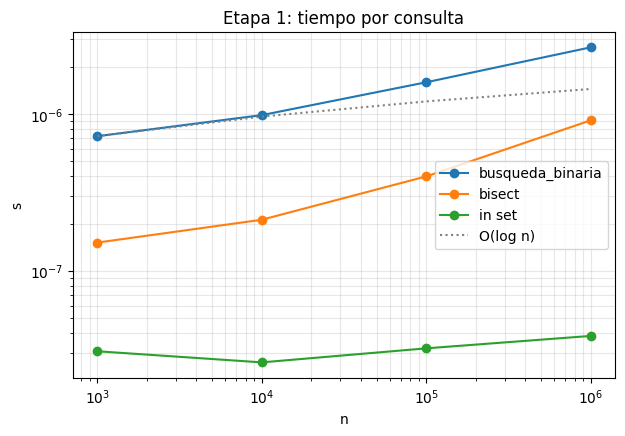

In [13]:
CONSULTAS = 10_000
tiempos_busqueda = {}
for n in TAMANOS_E1:
    datos = sorted(rng.sample(range(10 * n), n))
    conjunto = set(datos)
    objetivos = [rng.randrange(10 * n) for _ in range(CONSULTAS)]
    casos = {
        "busqueda_binaria": lambda: [busqueda_binaria(datos, x) for x in objetivos],
        "bisect": lambda: [bisect.bisect_left(datos, x) for x in objetivos],
        "in set": lambda: [x in conjunto for x in objetivos],
    }
    for nombre, fn in casos.items():
        prom, _ = medir(fn, 20)
        tiempos_busqueda.setdefault(nombre, {})[n] = prom / CONSULTAS
        print(f"n={n:>9,}  {nombre:16} {prom / CONSULTAS * 1e6:7.3f} µs/consulta")

graficar_loglog(tiempos_busqueda, "Etapa 1: tiempo por consulta", referencias=("log n",))

### 1.5 Deduplicación: `Preprocesador` vs `set` + `deque`
La alternativa exacta y simple guarda las últimas W claves en un `set` y usa una `deque` para saber
cuál vencer. Reutiliza la validación y la clave de `Preprocesador`, así que solo cambia la estructura
de la ventana. Se usa el primer millón de filas reales, en lotes de 10K y ventana de 100K.

In [14]:
from pipeline_eda.etapa0_ingesta import leer_csv


class DedupSet:
    """Ventana de las últimas `ventana` claves en un set; la deque recuerda el orden para vencerlas."""

    def __init__(self, ventana):
        self.ventana = ventana
        self.vistas = set()
        self.orden = deque()
        self._p = Preprocesador()

    def procesar(self, lote):
        salida = []
        for ev in lote:
            if self._p._motivo_invalido(ev) is not None:
                continue
            k = Preprocesador.clave(self._p._normalizar(ev))
            if k in self.vistas:
                continue
            self.vistas.add(k)
            self.orden.append(k)
            salida.append(ev)
            if len(self.orden) > self.ventana:
                self.vistas.discard(self.orden.popleft())
        return salida


N_DEDUP, TAM_LOTE, VENTANA = 1_000_000, 10_000, 100_000
eventos = list(islice(leer_csv(CSV_REAL), N_DEDUP))
lotes = [eventos[i:i + TAM_LOTE] for i in range(0, len(eventos), TAM_LOTE)]


def correr(clase):
    d = clase(VENTANA)
    return [ev for lote in lotes for ev in d.procesar(lote)], d


salida_pre, pre = correr(Preprocesador)
salida_set, _ = correr(DedupSet)
assert sorted(map(Preprocesador.clave, salida_pre)) == sorted(map(Preprocesador.clave, salida_set))
print(f"Misma salida: {len(salida_pre):,} eventos emitidos de {len(eventos):,}")
pre.metricas()

Misma salida: 997,891 eventos emitidos de 1,000,000


{'recibidos': 1000000,
 'invalidos': 1607,
 'invalidos_por_motivo': {'precio': 1607},
 'duplicados_lote': 501,
 'duplicados_ventana': 1,
 'emitidos': 997891,
 'tamano_ventana': 100000}

In [15]:
for nombre, clase in (("Preprocesador (lista ordenada + búsqueda binaria)", Preprocesador),
                     ("DedupSet (set + deque)", DedupSet)):
    prom, desv = medir(lambda: correr(clase), 3)
    pico = memoria_pico(lambda: correr(clase))
    print(f"{nombre:50} {prom:6.2f} s ± {desv:.2f}   pico {pico / 1e6:7.1f} MB")

Preprocesador (lista ordenada + búsqueda binaria)    3.85 s ± 0.04   pico   104.2 MB


DedupSet (set + deque)                               0.83 s ± 0.04   pico   105.7 MB


## Etapa 2 — Cola con prioridades: `HeapMin` y `ColaPrioridad`

### 2.1 Correctitud
`HeapMin` contra `heapq` con operaciones al azar (a igual prioridad, sale primero el que llegó antes),
`prioridad_de` y una alerta que llega en medio de un lote.

In [16]:
import heapq
from datetime import datetime, timezone

from pipeline_eda.etapa2_prioridad import ColaPrioridad, HeapMin, prioridad_de
from pipeline_eda.evento import Alerta, Event, Prioridad

rng = random.Random(SEED)
for _ in range(500):
    heap, ref, secuencia = HeapMin(), [], 0
    for _ in range(rng.randint(0, 200)):
        if ref and rng.random() < 0.4:
            assert heap.pop() == heapq.heappop(ref)[2]
        else:
            secuencia += 1
            prioridad = rng.randint(0, 4)
            heap.push(prioridad, secuencia, f"x{secuencia}")
            heapq.heappush(ref, (prioridad, secuencia, f"x{secuencia}"))
    while ref:
        assert heap.pop() == heapq.heappop(ref)[2]


def evento(tipo, envio=None):
    return Event(datetime(2019, 10, 1, tzinfo=timezone.utc), tipo, 1, 1, None, None, 10.0, 1, "s", tipo_envio=envio)


assert prioridad_de(evento("view")) == prioridad_de(evento("cart")) == Prioridad.NAVEGACION
assert prioridad_de(evento("purchase", "express")) == Prioridad.EXPRESS
assert prioridad_de(evento("purchase", "estandar")) == Prioridad.ESTANDAR
assert prioridad_de(evento("purchase", "programada")) == Prioridad.PROGRAMADA

cola = ColaPrioridad()
lote = [evento("view"), evento("purchase", "programada"), evento("purchase", "express"),
        evento("cart"), evento("purchase", "estandar"), evento("purchase", "express")]
for ev in lote:
    cola.push_evento(ev)
assert cola.pop() is lote[2]  # el primer express
alerta = Alerta("senalada", "R001", 6, evento("purchase", "estandar"))
cola.push_alerta(alerta)
assert cola.pop() is alerta  # la alerta se adelanta a todo lo que queda
assert [cola.pop() for _ in range(len(cola))] == [lote[5], lote[4], lote[1], lote[0], lote[3]]
print("HeapMin == heapq; prioridades y alertas en el orden esperado", cola.metricas())

HeapMin == heapq; prioridades y alertas en el orden esperado {'encolados_por_prioridad': {'ALERTA': 1, 'EXPRESS': 2, 'ESTANDAR': 1, 'PROGRAMADA': 1, 'NAVEGACION': 2}, 'tamano_max': 6}


### 2.2 `HeapMin` vs `heapq`
Encolar n elementos con prioridades al azar (0–4) y sacarlos todos.

n=    1,000  HeapMin    0.00156 s ± 0.00005  (100 reps)
n=    1,000  heapq      0.00034 s ± 0.00003  (100 reps)


n=   10,000  HeapMin    0.02221 s ± 0.00041  (100 reps)


n=   10,000  heapq      0.00447 s ± 0.00009  (100 reps)


n=  100,000  HeapMin    0.31961 s ± 0.02173  (10 reps)


n=  100,000  heapq      0.06482 s ± 0.00488  (10 reps)


n=1,000,000  HeapMin    4.48431 s ± 0.07998  (3 reps)


n=1,000,000  heapq      1.34661 s ± 0.09148  (3 reps)


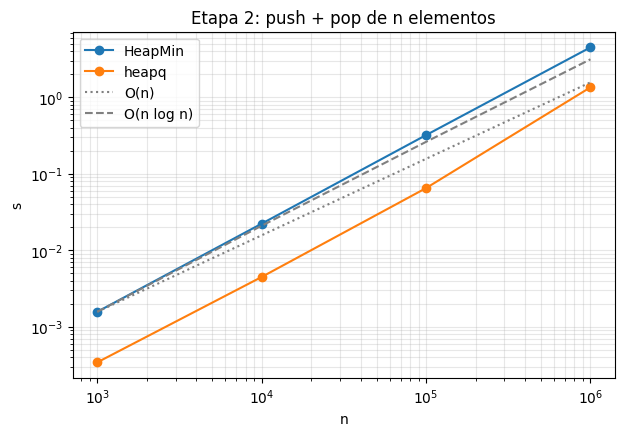

In [17]:
TAMANOS_E2 = [1_000, 10_000, 100_000, 1_000_000]
REPS_E2 = {1_000: 100, 10_000: 100, 100_000: 10, 1_000_000: 3}


def con_heap_min(prioridades):
    heap = HeapMin()
    for secuencia, prioridad in enumerate(prioridades):
        heap.push(prioridad, secuencia, None)
    for _ in prioridades:
        heap.pop()


def con_heapq(prioridades):
    heap = []
    for secuencia, prioridad in enumerate(prioridades):
        heapq.heappush(heap, (prioridad, secuencia, None))
    for _ in prioridades:
        heapq.heappop(heap)


tiempos_heap = {}
for n in TAMANOS_E2:
    prioridades = [rng.randint(0, 4) for _ in range(n)]
    for nombre, fn in (("HeapMin", con_heap_min), ("heapq", con_heapq)):
        prom, desv = medir(lambda: fn(prioridades), REPS_E2[n])
        tiempos_heap.setdefault(nombre, {})[n] = prom
        print(f"n={n:>9,}  {nombre:8} {prom:9.5f} s ± {desv:.5f}  ({REPS_E2[n]} reps)")

graficar_loglog(tiempos_heap, "Etapa 2: push + pop de n elementos", referencias=("n", "n log n"))

### 2.3 Con datos reales
Las primeras 100K filas pasan por las etapas 0 y 1 y luego por la cola, lote por lote, como en el
orquestador. Dentro de cada lote las compras salen antes que la navegación.

In [18]:
from pipeline_eda.etapa0_ingesta import Ingesta, leer_csv
from pipeline_eda.etapa1_preproceso import Preprocesador

e0, e1, cola = Ingesta(50_000, 10_000), Preprocesador(100_000), ColaPrioridad()
primer_lote = None
for lote in e0.lotes(leer_csv(CSV_REAL, limite=100_000)):
    for ev in e1.procesar(lote):
        cola.push_evento(ev)
    salida = [cola.pop() for _ in range(len(cola))]
    primer_lote = primer_lote or salida

print([prioridad_de(ev).name for ev in primer_lote[:200:20]])
cola.metricas()

['EXPRESS', 'EXPRESS', 'ESTANDAR', 'ESTANDAR', 'ESTANDAR', 'PROGRAMADA', 'NAVEGACION', 'NAVEGACION', 'NAVEGACION', 'NAVEGACION']


{'encolados_por_prioridad': {'ALERTA': 0,
  'EXPRESS': 315,
  'ESTANDAR': 1026,
  'PROGRAMADA': 344,
  'NAVEGACION': 98209},
 'tamano_max': 9946}

## Etapa 3 — Hash table, LRU y matriz dispersa

### 3.1 Correctitud
`TablaHash` contra `dict`, `CacheLRU` contra `OrderedDict` con operaciones al azar, y `CatalogoCache`
con un cambio de precio.

In [19]:
from collections import OrderedDict
from datetime import datetime, timezone

from pipeline_eda.etapa3_cache import CacheLRU, CatalogoCache, MatrizDispersa, TablaHash
from pipeline_eda.evento import Event

rng = random.Random(SEED)
tabla, ref = TablaHash(), {}
for _ in range(50_000):
    clave, op = rng.randint(0, 20_000), rng.random()
    if op < 0.6:
        valor = rng.random()
        tabla.put(clave, valor)
        ref[clave] = valor
    elif op < 0.8:
        assert tabla.eliminar(clave) == (ref.pop(clave, None) is not None)
    else:
        assert tabla.get(clave) == ref.get(clave) and (clave in tabla) == (clave in ref)
assert len(tabla) == len(ref) and sorted(tabla.valores()) == sorted(ref.values())

cache, ref = CacheLRU(100), OrderedDict()
for _ in range(50_000):
    clave = rng.randint(0, 300)
    if rng.random() < 0.5:
        esperado = ref.get(clave)
        if clave in ref:
            ref.move_to_end(clave)
        assert cache.get(clave) == esperado
    else:
        valor = rng.random()
        ref[clave] = valor
        ref.move_to_end(clave)
        if len(ref) > 100:
            ref.popitem(last=False)  # sale el usado hace más tiempo
        cache.put(clave, valor)
assert len(cache) == len(ref)

matriz = MatrizDispersa()
matriz.incrementar(1, 10, 1)
matriz.incrementar(1, 10, 5)
matriz.incrementar(2, 20)
assert matriz.valor(1, 10) == 6 and matriz.valor(3, 3) == 0 and matriz.fila(1) == {10: 6} and matriz.no_nulos == 2


def evento(tipo, producto, precio, usuario=1):
    return Event(datetime(2019, 10, 1, tzinfo=timezone.utc), tipo, producto, 7, None, "acme", precio, usuario, "s")


catalogo = CatalogoCache(capacidad_lru=2)
catalogo.consumir(evento("view", 1, 10.0))
catalogo.consumir(evento("purchase", 1, 10.0))
assert catalogo.obtener_producto(1).price == 10.0  # fallo: lo trae de la tabla y lo deja en la LRU
catalogo.consumir(evento("view", 1, 12.5))
assert catalogo.obtener_producto(1).price == 12.5  # acierto, y con el precio nuevo
assert catalogo.obtener_producto(99) is None
assert catalogo.interacciones.valor(1, 1) == 1 + 5 + 1
print("TablaHash == dict, CacheLRU == OrderedDict;", catalogo.metricas())

TablaHash == dict, CacheLRU == OrderedDict; {'productos': 1, 'tasa_aciertos_lru': 0.333, 'celdas_no_nulas': 1}


### 3.2 `TablaHash` vs `dict`
Insertar n claves y buscarlas todas.

n=    1,000  TablaHash    0.00092 s ± 0.00005  (100 reps)
n=    1,000  dict         0.00007 s ± 0.00002  (100 reps)


n=   10,000  TablaHash    0.02083 s ± 0.08110  (100 reps)
n=   10,000  dict         0.00066 s ± 0.00003  (100 reps)


n=  100,000  TablaHash    0.23473 s ± 0.16429  (10 reps)
n=  100,000  dict         0.01982 s ± 0.00170  (10 reps)


n=1,000,000  TablaHash    3.11143 s ± 0.16744  (3 reps)


n=1,000,000  dict         0.13518 s ± 0.01442  (3 reps)


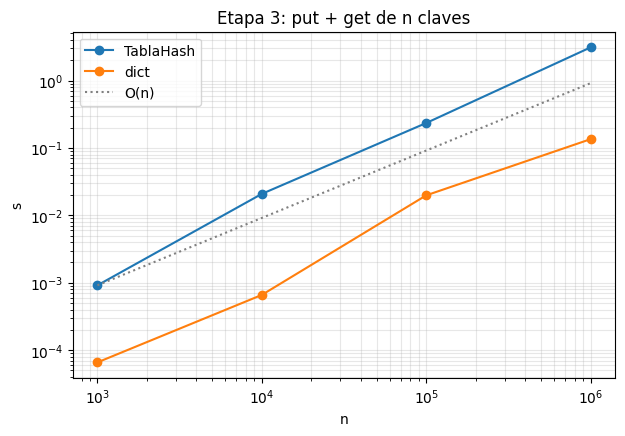

In [20]:
TAMANOS_E3 = [1_000, 10_000, 100_000, 1_000_000]
REPS_E3 = {1_000: 100, 10_000: 100, 100_000: 10, 1_000_000: 3}


def con_tabla_hash(claves):
    tabla = TablaHash()
    for c in claves:
        tabla.put(c, c)
    for c in claves:
        tabla.get(c)


def con_dict(claves):
    d = {}
    for c in claves:
        d[c] = c
    for c in claves:
        d.get(c)


tiempos_hash = {}
for n in TAMANOS_E3:
    claves = rng.sample(range(10 * n), n)
    for nombre, fn in (("TablaHash", con_tabla_hash), ("dict", con_dict)):
        prom, desv = medir(lambda: fn(claves), REPS_E3[n])
        tiempos_hash.setdefault(nombre, {})[n] = prom
        print(f"n={n:>9,}  {nombre:10} {prom:9.5f} s ± {desv:.5f}  ({REPS_E3[n]} reps)")

graficar_loglog(tiempos_hash, "Etapa 3: put + get de n claves", referencias=("n",))

### 3.3 `CatalogoCache` con datos reales
Las primeras 100K filas pasan por las etapas 0 y 1 y luego por el catálogo. Después se consultan
productos con la misma frecuencia con que aparecen en el stream (los populares se repiten), y se
compara la tasa de aciertos de la LRU según su capacidad.

In [21]:
from pipeline_eda.etapa0_ingesta import Ingesta, leer_csv
from pipeline_eda.etapa1_preproceso import Preprocesador

e0, e1 = Ingesta(50_000, 10_000), Preprocesador(100_000)
eventos_e3 = [ev for lote in e0.lotes(leer_csv(CSV_REAL, limite=100_000)) for ev in e1.procesar(lote)]
consultas = [ev.product_id for ev in rng.sample(eventos_e3, 20_000)]

for capacidad in (100, 1_000, 10_000):
    catalogo = CatalogoCache(capacidad)
    for ev in eventos_e3:
        catalogo.consumir(ev)
    for pid in consultas:
        catalogo.obtener_producto(pid)
    print(f"LRU de {capacidad:>6,}:", catalogo.metricas())

LRU de    100: {'productos': 20561, 'tasa_aciertos_lru': 0.074, 'celdas_no_nulas': 65846}
LRU de  1,000: {'productos': 20561, 'tasa_aciertos_lru': 0.291, 'celdas_no_nulas': 65846}


LRU de 10,000: {'productos': 20561, 'tasa_aciertos_lru': 0.568, 'celdas_no_nulas': 65846}


## Etapa 4 — B+Tree

Pruebas traídas de los scripts `probar_*.py` y `benchmark_bplustree.py` de la rama
`mi-trabajo-etapas-4-5-7`, convertidas a `assert`.

### 4.1 `BPlusTree`: búsqueda, rangos y claves repetidas
Orden 4 para forzar divisiones con pocas claves.

In [22]:
from pipeline_eda.etapa4_bplustree import BPlusTree, IndiceProductos
from pipeline_eda.evento import Event

# Claves desordenadas y una repetida
arbol = BPlusTree(orden=4)
for clave, valor in [(50, "A"), (20, "B"), (40, "C"), (10, "D"), (30, "E"), (20, "F"), (60, "G")]:
    arbol.insertar(clave, valor)

assert arbol.buscar(20) == ["B", "F"]
assert arbol.buscar(999) == []
assert list(arbol.rango(10, 60)) == [(10, "D"), (20, "B"), (20, "F"), (30, "E"), (40, "C"), (50, "A"), (60, "G")]
assert list(arbol.rango(70, 90)) == []                                 # sin resultados
assert list(arbol.rango(50, 20)) == []                                 # rango invertido
assert list(arbol.rango(20, 20)) == [(20, "B"), (20, "F")]             # una sola clave
assert list(arbol.rango(20, 35)) == [(20, "B"), (20, "F"), (30, "E")]  # un extremo no existe
assert arbol.metricas()["claves_indexadas"] == 6
arbol.metricas()

{'claves_indexadas': 6,
 'altura': 2,
 'consultas': 6,
 'paginas_leidas_ultima_consulta': 3,
 'paginas_leidas_total': 14}

In [23]:
# Muchas inserciones en orden con orden 4: el árbol crece en altura
for n in (100, 10_000):
    arbol = BPlusTree(orden=4)
    for i in range(1, n + 1):
        arbol.insertar(i, f"producto_{i}")
    assert arbol.metricas()["claves_indexadas"] == n
    assert arbol.buscar(n * 3 // 4) == [f"producto_{n * 3 // 4}"]
    assert list(arbol.rango(n // 2, n // 2 + 5)) == [(i, f"producto_{i}") for i in range(n // 2, n // 2 + 6)]
    print(f"n={n:>6,}", arbol.metricas())

n=   100 {'claves_indexadas': 100, 'altura': 5, 'consultas': 2, 'paginas_leidas_ultima_consulta': 8, 'paginas_leidas_total': 13}


n=10,000 {'claves_indexadas': 10000, 'altura': 9, 'consultas': 2, 'paginas_leidas_ultima_consulta': 12, 'paginas_leidas_total': 21}


In [24]:
# Contra una referencia de Python: dict clave -> valores, y rangos sobre sorted()
rng = random.Random(SEED)
for orden in (3, 4, 64):
    arbol, ref = BPlusTree(orden=orden), {}
    for i in range(5_000):
        clave = rng.randint(0, 2_000)
        arbol.insertar(clave, i)
        ref.setdefault(clave, []).append(i)
    for _ in range(200):
        a, b = sorted(rng.randint(-10, 2_010) for _ in range(2))
        assert list(arbol.rango(a, b)) == [(k, v) for k in sorted(ref) if a <= k <= b for v in ref[k]]
        assert arbol.buscar(a) == ref.get(a, [])
print("BPlusTree == dict + sorted() en buscar y rango (órdenes 3, 4 y 64)")

BPlusTree == dict + sorted() en buscar y rango (órdenes 3, 4 y 64)


### 4.2 `IndiceProductos`: cambios de precio, NaN y precios límite

In [25]:
def evento(tiempo, producto, precio):
    return Event(event_time=tiempo, event_type="view", product_id=producto, category_id=1,
                 category_code=None, brand=None, price=precio, user_id=100 + producto,
                 user_session=f"sesion_{producto}")


# Cambios de precio: solo cuenta el precio actual de cada producto
indice = IndiceProductos(orden=4)
for t, prod, precio in [(100, 1, 10.0), (200, 2, 20.0), (300, 1, 15.0), (300, 3, 15.0)]:
    indice.consumir(evento(t, prod, precio))
assert indice.productos_en_rango_precio(15.0, 15.0) == [1, 3]
assert indice.productos_en_rango_precio(10.0, 10.0) == []  # precio anterior del producto 1
assert [(e.event_time, e.product_id, e.price) for e in indice.eventos_en_rango_tiempo(200, 300)] == \
    [(200, 2, 20.0), (300, 1, 15.0), (300, 3, 15.0)]

indice.consumir(evento(400, 1, 25.0))
indice.consumir(evento(500, 1, 30.0))
assert indice.productos_en_rango_precio(30.0, 30.0) == [1]
assert indice.productos_en_rango_precio(25.0, 25.0) == []
assert indice.productos_en_rango_precio(15.0, 15.0) == [3]
assert [(e.event_time, e.price) for e in indice.eventos_en_rango_tiempo(100, 500) if e.product_id == 1] == \
    [(100, 10.0), (300, 15.0), (400, 25.0), (500, 30.0)]  # historial del producto 1
indice.metricas()

{'eventos_procesados': 6,
 'productos_indexados': 3,
 'arbol_precio': {'claves_indexadas': 5,
  'altura': 2,
  'consultas': 5,
  'paginas_leidas_ultima_consulta': 3,
  'paginas_leidas_total': 9},
 'arbol_tiempo': {'claves_indexadas': 5,
  'altura': 2,
  'consultas': 2,
  'paginas_leidas_ultima_consulta': 3,
  'paginas_leidas_total': 4}}

In [26]:
# NaN y negativos no se indexan por precio: el producto conserva su último precio válido
indice = IndiceProductos(orden=4)
indice.consumir(evento(100, 1, 25.0))
indice.consumir(evento(200, 1, float("nan")))
indice.consumir(evento(300, 1, -5.0))
assert indice.productos_en_rango_precio(25, 25) == [1]
assert indice.productos_en_rango_precio(-10, -1) == []

# Precio 0 sí se indexa (en el pipeline la etapa 1 ya descarta precio <= 0)
indice = IndiceProductos(orden=4)
for prod, precio in [(1, 0.0), (2, -5.0), (3, 10.0)]:
    indice.consumir(evento(100, prod, precio))
assert indice.productos_en_rango_precio(0, 0) == [1]
assert indice.productos_en_rango_precio(-10, -1) == []
assert indice.productos_en_rango_precio(1, 20) == [3]
print("IndiceProductos OK")

IndiceProductos OK


### 4.3 Volumen de `IndiceProductos`
1.000 productos con 20 precios posibles; cada evento entra al índice de tiempo.

In [27]:
for n in (10_000, 100_000):
    indice = IndiceProductos(orden=64)
    inicio = time.perf_counter()
    for i in range(n):
        producto = (i % 1000) + 1
        indice.consumir(evento(i, producto, 10.0 + (i % 20)))
    m = indice.metricas()
    print(f"n={n:>7,}  {time.perf_counter() - inicio:.3f} s  productos={m['productos_indexados']}  "
          f"claves precio={m['arbol_precio']['claves_indexadas']} (altura {m['arbol_precio']['altura']})  "
          f"claves tiempo={m['arbol_tiempo']['claves_indexadas']:,} (altura {m['arbol_tiempo']['altura']})")

n= 10,000  0.015 s  productos=1000  claves precio=20 (altura 1)  claves tiempo=10,000 (altura 3)


n=100,000  0.246 s  productos=1000  claves precio=20 (altura 1)  claves tiempo=100,000 (altura 4)


### 4.4 B+Tree vs lista ordenada + `bisect`
Mismos datos y mismo orden de inserción (al azar) para ambas estructuras.

- **Corrección respecto de `benchmark_bplustree.py`:** allí las consultas llamaban a `arbol.rango(...)`
  sin consumir el generador, así que la búsqueda no llegaba a ejecutarse y el B+Tree aparecía 10–20x
  más rápido. Aquí se consume con `list(...)`, y la búsqueda exacta usa `buscar`. Los números fijos de
  `resumen_benchmark.py` se reemplazan por esta medición.
- Construir la lista con `insort` es O(n²) por los corrimientos, por eso el tamaño máximo es 200K.

In [28]:
TAMANOS_E4 = [1_000, 10_000, 100_000, 200_000]
NUM_CONSULTAS, NUM_RANGOS, ANCHO_RANGO = 1_000, 100, 20

construccion, memoria_e4, exacta, por_rango = {}, {}, {}, {}
for n in TAMANOS_E4:
    rng = random.Random(SEED)
    datos = list(range(1, n + 1))
    rng.shuffle(datos)
    consultas = rng.sample(range(1, n + 1), NUM_CONSULTAS)
    rangos = [(x, x + ANCHO_RANGO) for x in consultas[:NUM_RANGOS]]

    def construir_bplus():
        arbol = BPlusTree(orden=64)
        for clave in datos:
            arbol.insertar(clave, clave)
        return arbol

    def construir_lista():
        lista = []
        for clave in datos:
            bisect.insort(lista, (clave, clave))
        return lista

    arbol, lista = construir_bplus(), construir_lista()
    casos = {
        "B+Tree": (construir_bplus,
                   lambda: [arbol.buscar(c) for c in consultas],
                   lambda: [list(arbol.rango(a, b)) for a, b in rangos]),
        "lista + bisect": (construir_lista,
                           lambda: [lista[bisect.bisect_left(lista, (c, -math.inf)):bisect.bisect_right(lista, (c, math.inf))]
                                    for c in consultas],
                           lambda: [lista[bisect.bisect_left(lista, (a, -math.inf)):bisect.bisect_right(lista, (b, math.inf))]
                                    for a, b in rangos]),
    }
    for nombre, (construir, buscar_exacta, buscar_rango) in casos.items():
        t_constr, _ = medir(construir, 3 if n <= 10_000 else 1)
        pico = memoria_pico(construir) if n <= 100_000 else None
        t_exacta, _ = medir(buscar_exacta, 20)
        t_rango, _ = medir(buscar_rango, 20)
        construccion.setdefault(nombre, {})[n] = t_constr
        exacta.setdefault(nombre, {})[n] = t_exacta / NUM_CONSULTAS
        por_rango.setdefault(nombre, {})[n] = t_rango / NUM_RANGOS
        pico_txt = f"{pico / 1e6:6.2f} MB" if pico is not None else "     —   "
        print(f"n={n:>7,}  {nombre:15} construcción {t_constr:8.4f} s  pico {pico_txt}  "
              f"exacta {t_exacta / NUM_CONSULTAS * 1e6:6.2f} µs  rango {t_rango / NUM_RANGOS * 1e6:6.2f} µs")

n=  1,000  B+Tree          construcción   0.0005 s  pico   0.08 MB  exacta   0.46 µs  rango   2.68 µs
n=  1,000  lista + bisect  construcción   0.0003 s  pico   0.01 MB  exacta   0.70 µs  rango   0.76 µs
n= 10,000  B+Tree          construcción   0.0058 s  pico   0.88 MB  exacta   0.55 µs  rango   2.82 µs
n= 10,000  lista + bisect  construcción   0.0067 s  pico   0.60 MB  exacta   0.87 µs  rango   1.01 µs


n=100,000  B+Tree          construcción   0.0995 s  pico   8.87 MB  exacta   0.67 µs  rango   3.05 µs


n=100,000  lista + bisect  construcción   0.5288 s  pico   7.07 MB  exacta   1.11 µs  rango   1.12 µs


n=200,000  B+Tree          construcción   0.2966 s  pico      —     exacta   0.78 µs  rango   3.23 µs


n=200,000  lista + bisect  construcción   1.9705 s  pico      —     exacta   1.18 µs  rango   1.19 µs


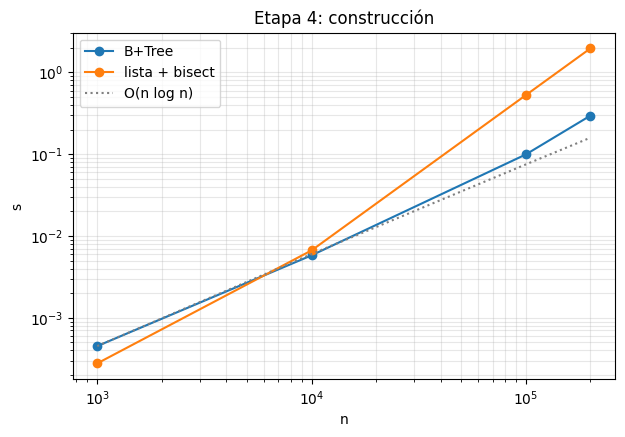

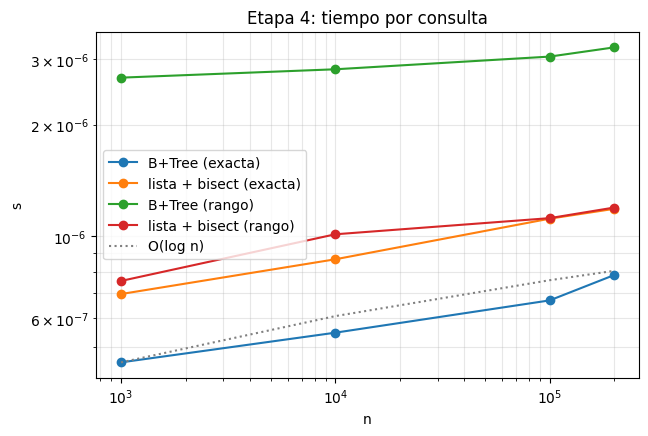

In [29]:
graficar_loglog(construccion, "Etapa 4: construcción", referencias=("n log n",))
graficar_loglog({f"{k} (exacta)": v for k, v in exacta.items()} | {f"{k} (rango)": v for k, v in por_rango.items()},
                "Etapa 4: tiempo por consulta", referencias=("log n",))

## Etapa 5 — KD-Tree y KNN exacto

Pruebas traídas de los scripts `probar_etapa5_*.py` de la rama `mi-trabajo-etapas-4-5-7`, convertidas a `assert`.
Cada producto es `(precio normalizado, category_id)` y la distancia es
`sqrt(Δprecio² + (0 si es la misma categoría, 1 si no))`. El árbol corta solo por precio.

### 5.1 Correctitud: `KDTree` e `IndiceKD` contra `knn_exacto`

In [30]:
from pipeline_eda.etapa5_kdtree import IndiceKD, KDTree, distancia_mixta, knn_exacto
from pipeline_eda.evento import Producto

# Casos límite
arbol = KDTree()
assert arbol.knn((0.5, 1), 3) == []  # árbol vacío
arbol.construir([(0.1, 1), (0.2, 2), (0.3, 3)], [101, 102, 103])
assert arbol.knn((0.1, 1), 0) == [] and arbol.knn((0.1, 1), -1) == []
assert [pid for _, pid in arbol.knn((0.1, 1), 10)] == [101, 102, 103]  # k mayor que el árbol

# Empates: puntos idénticos y puntos a la misma distancia se desempatan por product_id
for puntos, q, k in [([(0.1, 1)] * 3 + [(0.2, 2)], (0.1, 1), 3),
                     ([(0.6, 1), (0.4, 1), (0.5, 2), (0.9, 1)], (0.5, 1), 3)]:
    ids = list(range(201, 201 + len(puntos)))
    arbol.construir(puntos, ids)
    assert arbol.knn(q, k) == knn_exacto(puntos, ids, q, k)

# Rango por precio y categoría
arbol.construir([(0.1, 1), (0.2, 2), (0.3, 3), (0.4, 4), (0.5, 5)], [101, 102, 103, 104, 105])
assert arbol.rango((0.2, 2), (0.4, 4)) == [102, 103, 104]
assert arbol.rango((0.6, 6), (0.9, 9)) == []

# Contra fuerza bruta con puntos al azar
rng = random.Random(SEED)
puntos = [(rng.random(), rng.randint(1, 20)) for _ in range(1_000)]
ids = list(range(1, 1_001))
arbol.construir(puntos, ids)
for _ in range(200):
    q = (rng.random(), rng.randint(1, 20))
    assert arbol.knn(q, 10) == knn_exacto(puntos, ids, q, 10)
print("KDTree.knn == knn_exacto (casos límite, empates y 200 consultas al azar)")

KDTree.knn == knn_exacto (casos límite, empates y 200 consultas al azar)


In [31]:
# IndiceKD: normalización min-max sobre el catálogo y category_id reales (enteros grandes)
CAT_A, CAT_B, CAT_C, CAT_D = 2103807459595380000, 2053013552326770000, 2053013559792630000, 2053013558920210000


def producto(pid, categoria, precio):
    return Producto(pid, categoria, None, None, precio)


productos = [producto(1, CAT_A, 0.79), producto(2, CAT_A, 10.0), producto(3, CAT_A, 35.79), producto(4, CAT_A, 251.74),
             producto(5, CAT_A, 275.0), producto(6, CAT_B, 33.2), producto(7, CAT_C, 543.1), producto(8, CAT_D, 3000.0)]
indice = IndiceKD()
indice.construir(productos)
punto = dict(zip(indice.ids, indice.puntos))
assert (indice.precio_min, indice.precio_max) == (0.79, 3000.0)
assert punto[1][0] == 0.0 and punto[8][0] == 1.0
assert punto[4][1] == CAT_A  # la categoría se guarda como int, sin pérdida de precisión
assert distancia_mixta(punto[4], punto[5]) < 1 <= distancia_mixta(punto[4], punto[6])  # otra categoría suma 1

esperado = [pid for _, pid in knn_exacto(indice.puntos, indice.ids, punto[4], 6) if pid != 4][:5]
assert indice.similares(4, 5) == esperado == [5, 3, 2, 1, 6]  # primero su categoría, luego las demás
assert indice.similares(999_999, 3) == [] and indice.similares(4, 0) == []

iguales = IndiceKD()
iguales.construir([producto(10, CAT_A, 100.0), producto(11, CAT_B, 100.0)])
assert iguales.similares(10, 1) == [11]  # precio_min == precio_max: todo se normaliza a 0
indice.metricas()

{'puntos_indexados': 8,
 'profundidad': 4,
 'nodos_visitados_ultima_consulta': 8,
 'precio_min': 0.79,
 'precio_max': 3000.0}

### 5.2 `KDTree` vs `knn_exacto` (fuerza bruta)
Productos sintéticos como en `probar_etapa5_pruebas_nuevadisteuc.py`: precios entre 0.79 y 3000, con más
productos baratos que caros, y 4 categorías. Cada consulta es un producto del catálogo con k = 10, y cada una
cuenta como una repetición (100; en 1M, 10, porque la fuerza bruta tarda ~1 s por consulta). Ambos métodos
deben devolver los mismos vecinos.

In [32]:
TAMANOS_E5 = [1_000, 10_000, 100_000, 1_000_000]
CONSULTAS_E5 = {1_000: 100, 10_000: 100, 100_000: 100, 1_000_000: 10}
K = 10


def cronometrar(fn):
    inicio = time.perf_counter()
    resultado = fn()
    return resultado, time.perf_counter() - inicio


construccion_e5, consulta_e5 = {}, {}
for n in TAMANOS_E5:
    rng = random.Random(SEED)
    productos = [producto(pid, rng.choice((CAT_A, CAT_B, CAT_C, CAT_D)), round(0.79 + rng.random() ** 2 * 2999.21, 2))
                 for pid in range(1, n + 1)]
    indice = IndiceKD()
    t_constr, _ = medir(lambda: indice.construir(productos), 3 if n <= 100_000 else 1)
    pico = memoria_pico(lambda: IndiceKD().construir(productos)) if n <= 100_000 else None

    punto = dict(zip(indice.ids, indice.puntos))
    tiempos, nodos = {"KD-Tree": [], "fuerza bruta": []}, []
    for pid in rng.sample(indice.ids, CONSULTAS_E5[n]):
        q = punto[pid]
        kd, t_kd = cronometrar(lambda: indice.arbol.knn(q, K))
        nodos.append(indice.arbol.nodos_visitados)
        exacto, t_exacto = cronometrar(lambda: knn_exacto(indice.puntos, indice.ids, q, K))
        assert kd == exacto
        tiempos["KD-Tree"].append(t_kd)
        tiempos["fuerza bruta"].append(t_exacto)

    construccion_e5.setdefault("IndiceKD.construir", {})[n] = t_constr
    for nombre, ts in tiempos.items():
        consulta_e5.setdefault(nombre, {})[n] = statistics.mean(ts)
    pico_txt = f"{pico / 1e6:6.2f} MB" if pico is not None else "     —   "
    print(f"n={n:>9,}  construcción {t_constr:7.3f} s  pico {pico_txt}  "
          + "  ".join(f"{nombre} {statistics.mean(ts) * 1e3:8.3f} ± {statistics.stdev(ts) * 1e3:6.3f} ms"
                      for nombre, ts in tiempos.items())
          + f"  nodos visitados (mediana) {statistics.median(nodos):>7,.0f}")

n=    1,000  construcción   0.002 s  pico   0.31 MB  KD-Tree    0.034 ±  0.009 ms  fuerza bruta    0.320 ±  0.005 ms  nodos visitados (mediana)      52


n=   10,000  construcción   0.020 s  pico   3.65 MB  KD-Tree    0.039 ±  0.011 ms  fuerza bruta    3.929 ±  0.203 ms  nodos visitados (mediana)      57


n=  100,000  construcción   0.344 s  pico  40.89 MB  KD-Tree    0.067 ±  0.014 ms  fuerza bruta   62.172 ±  5.509 ms  nodos visitados (mediana)      60


n=1,000,000  construcción   7.871 s  pico      —     KD-Tree    0.141 ±  0.025 ms  fuerza bruta 1123.177 ± 42.717 ms  nodos visitados (mediana)      72


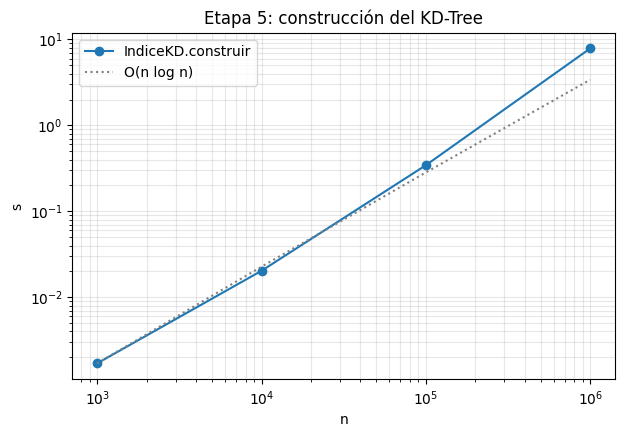

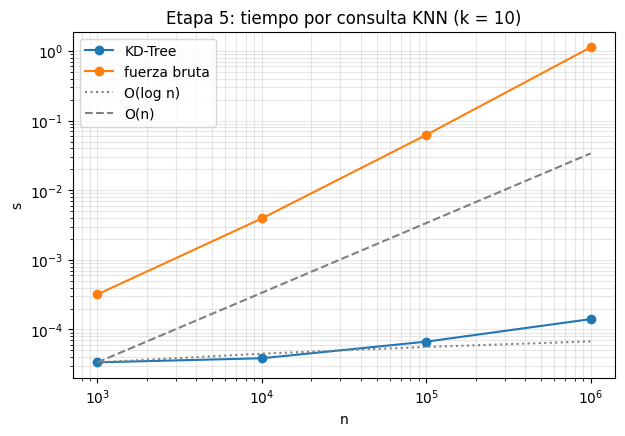

In [33]:
graficar_loglog(construccion_e5, "Etapa 5: construcción del KD-Tree", referencias=("n log n",))
graficar_loglog(consulta_e5, "Etapa 5: tiempo por consulta KNN (k = 10)", referencias=("log n", "n"))

### 5.3 Integración con datos reales
Las primeras 1M filas pasan por las etapas 0 → 1 → 2 → 3, y el KD-Tree se construye con `productos()` de
la etapa 3, igual que en `Pipeline._cerrar`. Se piden los 10 similares de 100 productos al azar y se comparan
con `knn_exacto`. Si la categoría del producto tiene menos de k productos, la cota de poda llega a 1 y el árbol
recorre casi todo: eso explica el máximo de nodos visitados.

In [34]:
from pipeline_eda.etapa0_ingesta import Ingesta, leer_csv
from pipeline_eda.etapa1_preproceso import Preprocesador
from pipeline_eda.etapa2_prioridad import ColaPrioridad
from pipeline_eda.etapa3_cache import CatalogoCache

e0, e1, e2, e3 = Ingesta(50_000, 10_000), Preprocesador(100_000), ColaPrioridad(), CatalogoCache(10_000)
for lote in e0.lotes(leer_csv(CSV_REAL, limite=1_000_000)):
    for ev in e1.procesar(lote):
        e2.push_evento(ev)
    while len(e2):
        e3.consumir(e2.pop())

e5 = IndiceKD()
e5.construir(e3.productos())
punto = dict(zip(e5.ids, e5.puntos))
rng = random.Random(SEED)
nodos = []
for pid in rng.sample(e5.ids, 100):
    esperado = [p for _, p in knn_exacto(e5.puntos, e5.ids, punto[pid], K + 1) if p != pid][:K]
    assert e5.similares(pid, K) == esperado
    nodos.append(e5.arbol.nodos_visitados)
print(f"{len(e5.ids):,} productos de {len({p.category_id for p in e5.productos.values()})} categorías; "
      f"nodos visitados por consulta: mediana {statistics.median(nodos):,.0f}, máximo {max(nodos):,}")
e5.metricas()

62,950 productos de 544 categorías; nodos visitados por consulta: mediana 1,081, máximo 30,478


{'puntos_indexados': 62950,
 'profundidad': 16,
 'nodos_visitados_ultima_consulta': 193,
 'precio_min': 0.79,
 'precio_max': 2574.07}

## Etapa 6 [FIJA] — Bloom Filter y Count-Min Sketch

El Bloom Filter guarda las tarjetas señaladas y el Count-Min Sketch cuenta los intentos de compra por tarjeta en
ventanas de 300 s; una tarjeta que supera 5 intentos en la ventana genera una alerta de intensidad. Las alertas de
tarjetas señaladas se verifican contra el conjunto exacto antes de bloquear; las de intensidad se confirman sin
verificar (6.4 muestra que el sketch no sobreestimó en ninguna alerta con datos reales).

### 6.1 Correctitud

In [4]:
from datetime import datetime, timedelta, timezone

from pipeline_eda.etapa6_probabilistico import BloomFilter, CountMinSketch, DetectorFraude
from pipeline_eda.evento import Event

# Bloom Filter: sin falsos negativos y tasa de FP cercana a la pedida
bloom = BloomFilter(10_000, 0.01)
for i in range(10_000):
    bloom.agregar(f"T{i}")
assert all(f"T{i}" in bloom for i in range(10_000))
fp = sum(f"X{i}" in bloom for i in range(100_000)) / 100_000
print(f"Bloom: m = {bloom.m:,} bits, k = {bloom.k}, tasa de FP {fp:.4f} (pedida 0.01)")
assert fp < 0.015

# Count-Min Sketch: nunca subestima, y el error supera e/w · total en a lo más una fracción δ = e^-d de las claves
def intentos(n):
    """n intentos sobre n/10 tarjetas; el cubo sesga hacia las primeras: pocas muy frecuentes y muchas raras."""
    rng, n_tarjetas = random.Random(SEED), max(10, n // 10)
    for _ in range(n):
        yield f"T{int(n_tarjetas * rng.random() ** 3)}"


cms, real = CountMinSketch(2_000, 5, SEED), {}
for clave in intentos(100_000):
    cms.agregar(clave)
    real[clave] = real.get(clave, 0) + 1
errores = [cms.estimar(clave) - n for clave, n in real.items()]
eps, delta = math.e / cms.ancho, math.exp(-cms.profundidad)
fuera = sum(e > eps * cms.total for e in errores) / len(errores)
print(f"CMS: {len(real):,} claves, error mínimo {min(errores)}, promedio {statistics.mean(errores):.1f}, "
      f"máximo {max(errores)} (cota e/w · total = {eps * cms.total:.0f}), fuera de la cota {fuera:.4f} (δ = {delta:.4f})")
assert min(errores) >= 0 and fuera <= delta

Bloom: m = 95,851 bits, k = 7, tasa de FP 0.0104 (pedida 0.01)


CMS: 9,902 claves, error mínimo 0, promedio 15.5, máximo 76 (cota e/w · total = 136), fuera de la cota 0.0000 (δ = 0.0067)


In [5]:
# DetectorFraude: lo que usa el orquestador
def compra(segundo, tarjeta):
    return Event(datetime(2019, 10, 1, tzinfo=timezone.utc) + timedelta(seconds=segundo), "purchase", 1, 1,
                 None, None, 10.0, 1, "s", card_id=tarjeta)


detector = DetectorFraude(ventana_seg=300, umbral=5, seed=SEED)
detector.cargar_senalados(["R001"])
alertas = [detector.consumir(compra(s, "T1")) for s in range(10)]  # ráfaga de 10 intentos en 10 s
assert alertas[:5] == [None] * 5 and [a.tipo for a in alertas[5:]] == ["intensidad"] * 5
assert [a.conteo_estimado for a in alertas[5:]] == [6, 7, 8, 9, 10] and all(map(detector.verificar, alertas[5:]))
assert detector.consumir(compra(400, "T1")) is None  # nueva ventana: el contador volvió a 0

alerta = detector.consumir(compra(401, "R001"))
assert alerta.tipo == "senalada" and detector.verificar(alerta)
# Con 1 tarjeta y p = 1 % el Bloom tiene 10 bits: es fácil encontrar una tarjeta real que da positivo
falsa = next(f"T{i}" for i in range(2, 10**6) if f"T{i}" in detector.senalados)
alerta = detector.consumir(compra(402, falsa))
assert alerta.tipo == "senalada" and not detector.verificar(alerta)  # falso positivo: se libera
detector.metricas()

{'alertas': {'senalada': 2, 'intensidad': 5},
 'confirmadas': 6,
 'falsos_positivos': 1,
 'ventanas': 2,
 'bits_bloom': 10,
 'k_bloom': 7,
 'contadores_cms': 10000}

### 6.2 `BloomFilter` vs `set`
Insertar n tarjetas distintas y consultar 100K tarjetas que no están (cada consulta que da positivo es un falso
positivo). Ambos con p = 1 %. La memoria pico incluye las claves que guarda el `set`; el Bloom solo guarda sus bits.

In [6]:
TAMANOS_E6 = [1_000, 10_000, 100_000, 1_000_000, 10_000_000]
REPS_E6 = {1_000: 100, 10_000: 100, 100_000: 10, 1_000_000: 3, 10_000_000: 1}
CONSULTAS_E6 = 100_000
ausentes = [f"X{i}" for i in range(CONSULTAS_E6)]


def construir_bloom(n):
    bloom = BloomFilter(n, 0.01)
    for i in range(n):
        bloom.agregar(f"T{i}")
    return bloom


def construir_set(n):
    return {f"T{i}" for i in range(n)}


construccion_e6, consulta_e6, memoria_e6 = {}, {}, {}
for n in TAMANOS_E6:
    for nombre, construir in (("BloomFilter", construir_bloom), ("set", construir_set)):
        t, sd = medir(lambda: construir(n), REPS_E6[n])
        pico = memoria_pico(lambda: construir(n))
        estructura = construir(n)
        positivos, t_consulta = cronometrar(lambda: sum(c in estructura for c in ausentes))
        construccion_e6.setdefault(nombre, {})[n] = t
        consulta_e6.setdefault(nombre, {})[n] = t_consulta / CONSULTAS_E6
        memoria_e6.setdefault(nombre, {})[n] = pico / 1e6
        print(f"n={n:>10,}  {nombre:<11}  construcción {t:8.4f} s ± {sd:.4f} ({REPS_E6[n]} reps)  "
              f"pico {pico / 1e6:8.3f} MB  consulta {t_consulta / CONSULTAS_E6 * 1e6:5.2f} µs  "
              f"tasa de FP {positivos / CONSULTAS_E6:.4f}")
        del estructura

n=     1,000  BloomFilter  construcción   0.0024 s ± 0.0000 (100 reps)  pico    0.002 MB  consulta  1.40 µs  tasa de FP 0.0101
n=     1,000  set          construcción   0.0001 s ± 0.0000 (100 reps)  pico    0.078 MB  consulta  0.06 µs  tasa de FP 0.0000


n=    10,000  BloomFilter  construcción   0.0233 s ± 0.0002 (100 reps)  pico    0.012 MB  consulta  1.35 µs  tasa de FP 0.0104
n=    10,000  set          construcción   0.0014 s ± 0.0000 (100 reps)  pico    0.983 MB  consulta  0.04 µs  tasa de FP 0.0000


n=   100,000  BloomFilter  construcción   0.2367 s ± 0.0050 (10 reps)  pico    0.120 MB  consulta  1.37 µs  tasa de FP 0.0095


n=   100,000  set          construcción   0.0174 s ± 0.0008 (10 reps)  pico    9.979 MB  consulta  0.06 µs  tasa de FP 0.0000


n= 1,000,000  BloomFilter  construcción   2.4952 s ± 0.0423 (3 reps)  pico    1.199 MB  consulta  1.42 µs  tasa de FP 0.0100


n= 1,000,000  set          construcción   0.2547 s ± 0.0089 (3 reps)  pico   81.444 MB  consulta  0.13 µs  tasa de FP 0.0000


n=10,000,000  BloomFilter  construcción  34.6345 s ± 0.0000 (1 reps)  pico   11.983 MB  consulta  1.63 µs  tasa de FP 0.0100


n=10,000,000  set          construcción   3.8460 s ± 0.0000 (1 reps)  pico  757.325 MB  consulta  0.31 µs  tasa de FP 0.0000


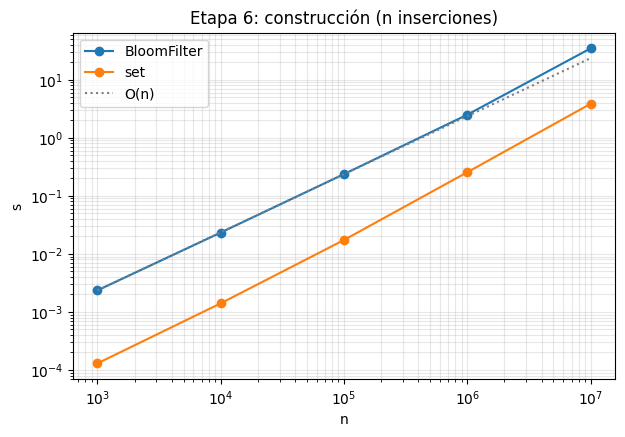

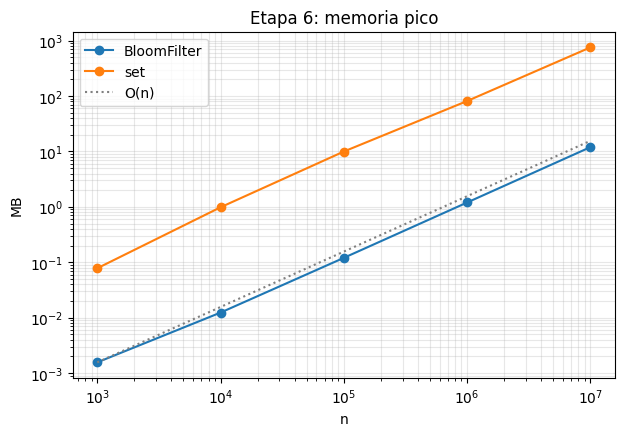

In [7]:
graficar_loglog(construccion_e6, "Etapa 6: construcción (n inserciones)", referencias=("n",))
graficar_loglog(memoria_e6, "Etapa 6: memoria pico", referencias=("n",), unidad="MB")

### 6.3 `CountMinSketch` vs `dict`
Stream de n intentos sobre n/10 tarjetas (`intentos` de 6.1): pocas tarjetas muy frecuentes y muchas raras. El sketch tiene ancho 2000 y profundidad 5, como en el pipeline, así que su memoria casi no depende de n,
pero su cota de error e/w · n crece con n; en el pipeline se reinicia cada 300 s, con unas pocas decenas de
intentos por ventana. Error = estimado − real, sobre todas las tarjetas distintas.

In [8]:
def contar_cms(n):
    cms = CountMinSketch(2_000, 5, SEED)
    for clave in intentos(n):
        cms.agregar(clave)
    return cms


def contar_dict(n):
    conteo = {}
    for clave in intentos(n):
        conteo[clave] = conteo.get(clave, 0) + 1
    return conteo


construccion_cms, memoria_cms = {}, {}
for n in TAMANOS_E6:
    for nombre, contar in (("CountMinSketch", contar_cms), ("dict", contar_dict)):
        t, sd = medir(lambda: contar(n), REPS_E6[n])
        pico = memoria_pico(lambda: contar(n))
        construccion_cms.setdefault(nombre, {})[n] = t
        memoria_cms.setdefault(nombre, {})[n] = pico / 1e6
        print(f"n={n:>10,}  {nombre:<14}  {t:8.4f} s ± {sd:.4f} ({REPS_E6[n]} reps)  pico {pico / 1e6:8.3f} MB")
    cms, real = contar_cms(n), contar_dict(n)
    errores = [cms.estimar(clave) - c for clave, c in real.items()]
    assert min(errores) >= 0
    print(f"    {len(real):,} tarjetas distintas  error promedio {statistics.mean(errores):.2f}  "
          f"máximo {max(errores):,}  cota e/w · n = {math.e / 2_000 * n:,.0f}  "
          f"fuera de la cota {sum(e > math.e / 2_000 * n for e in errores):,} "
          f"({sum(e > math.e / 2_000 * n for e in errores) / len(errores):.5f}; δ = 0.0067)")

n=     1,000  CountMinSketch    0.0019 s ± 0.0001 (100 reps)  pico    0.083 MB
n=     1,000  dict              0.0003 s ± 0.0000 (100 reps)  pico    0.011 MB
    99 tarjetas distintas  error promedio 0.00  máximo 0  cota e/w · n = 1  fuera de la cota 0 (0.00000; δ = 0.0067)


n=    10,000  CountMinSketch    0.0184 s ± 0.0004 (100 reps)  pico    0.083 MB


n=    10,000  dict              0.0029 s ± 0.0001 (100 reps)  pico    0.074 MB
    993 tarjetas distintas  error promedio 0.05  máximo 7  cota e/w · n = 14  fuera de la cota 0 (0.00000; δ = 0.0067)


n=   100,000  CountMinSketch    0.1818 s ± 0.0018 (10 reps)  pico    0.083 MB


n=   100,000  dict              0.0301 s ± 0.0008 (10 reps)  pico    0.665 MB


...

n= 1,000,000  dict              0.4049 s ± 0.0212 (3 reps)  pico    9.867 MB


    98,985 tarjetas distintas  error promedio 328.84  máximo 4,133  cota e/w · n = 1,359  fuera de la cota 1 (0.00001; δ = 0.0067)


n=10,000,000  CountMinSketch   18.8334 s ± 0.0000 (1 reps)  pico    0.402 MB


n=10,000,000  dict              6.4527 s ± 0.0000 (1 reps)  pico   79.586 MB


    990,245 tarjetas distintas  error promedio 4180.25  máximo 30,193  cota e/w · n = 13,591  fuera de la cota 5 (0.00001; δ = 0.0067)


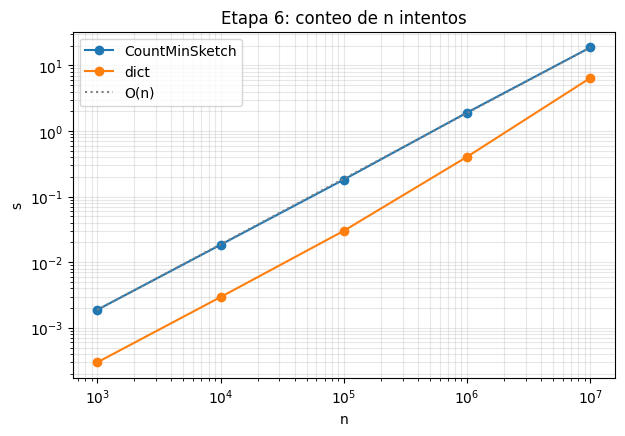

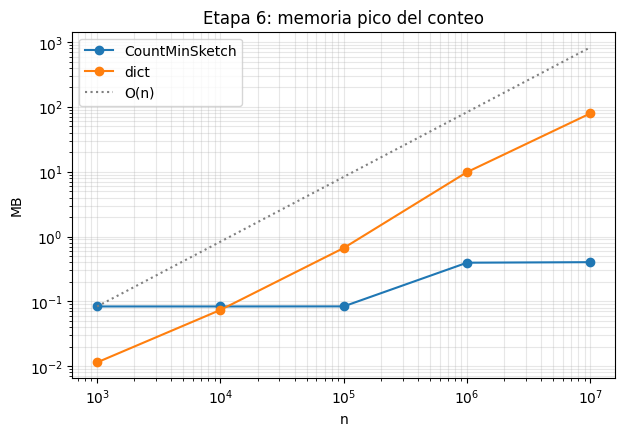

In [9]:
graficar_loglog(construccion_cms, "Etapa 6: conteo de n intentos", referencias=("n",))
graficar_loglog(memoria_cms, "Etapa 6: memoria pico del conteo", referencias=("n",), unidad="MB")

### 6.4 Integración con datos reales
Las 10M filas pasan por las etapas 0 → 1 → 2 → 6, con el mismo manejo de alertas que `Pipeline._drenar_heap`: la
alerta vuelve al heap con prioridad máxima y al salir se verifica; si se confirma, la compra se bloquea. Los
intentos de fraude de la etapa 0 traen `is_fraud`, con lo que se miden la precisión y el recall de los bloqueos.
En paralelo se cuentan los intentos exactos por tarjeta en la misma ventana, para medir cuánto sobreestimó el
sketch en las alertas.

Los primeros 5 intentos de una ráfaga con una tarjeta no señalada no superan el umbral y pasan: es lo que limita el
recall. Las alertas de intensidad que no son fraude son clientes reales con más de 5 compras en 5 minutos.

In [10]:
from collections import Counter

from pipeline_eda.etapa0_ingesta import Ingesta, leer_csv
from pipeline_eda.etapa1_preproceso import Preprocesador
from pipeline_eda.etapa2_prioridad import ColaPrioridad
from pipeline_eda.evento import Alerta

e0, e1, e2, e6 = Ingesta(50_000, 10_000), Preprocesador(100_000), ColaPrioridad(), DetectorFraude(seed=SEED)
e6.cargar_senalados(e0.senalados())
bloqueadas, compras, fraudes, exacto, excesos = [], 0, 0, {}, []
for lote in e0.lotes(leer_csv(CSV_REAL)):
    for ev in e1.procesar(lote):
        e2.push_evento(ev)
    while len(e2):
        item = e2.pop()
        if isinstance(item, Alerta):
            if e6.verificar(item):
                bloqueadas.append(item)
            continue
        if item.event_type != "purchase":
            continue
        compras += 1
        fraudes += item.is_fraud
        ventana = e6.ventanas
        alerta = e6.consumir(item)
        if e6.ventanas != ventana:  # el detector abrió una ventana nueva
            exacto.clear()
        exacto[item.card_id] = exacto.get(item.card_id, 0) + 1
        if alerta is not None:
            excesos.append(alerta.conteo_estimado - exacto[item.card_id])
            e2.push_alerta(alerta)

aciertos = sum(a.evento.is_fraud for a in bloqueadas)
print(f"{compras:,} compras, {fraudes:,} intentos de fraude, {len(bloqueadas):,} bloqueadas: "
      f"precisión {aciertos / len(bloqueadas):.3f}, recall {aciertos / fraudes:.3f}")
print("bloqueadas por (motivo, is_fraud):", dict(Counter((a.tipo, a.evento.is_fraud) for a in bloqueadas)))
negativos = compras - sum(a.tipo == "senalada" for a in bloqueadas)  # compras con tarjetas no señaladas
print(f"falsos positivos del Bloom liberados: {e6.falsos_positivos:,} "
      f"({e6.falsos_positivos / negativos:.4f} de las compras con tarjeta no señalada; pedida 0.01)")
print(f"sobreestimación del sketch en las {len(excesos):,} alertas: máximo {max(excesos)}, "
      f"alertas con exceso {sum(e > 0 for e in excesos)}")
e6.metricas()

176,496 compras, 3,660 intentos de fraude, 2,905 bloqueadas: precisión 0.939, recall 0.745
bloqueadas por (motivo, is_fraud): {('intensidad', False): 177, ('intensidad', True): 918, ('senalada', True): 1810}
falsos positivos del Bloom liberados: 1,471 (0.0084 de las compras con tarjeta no señalada; pedida 0.01)
sobreestimación del sketch en las 4,376 alertas: máximo 0, alertas con exceso 0


{'alertas': {'senalada': 3281, 'intensidad': 1095},
 'confirmadas': 2905,
 'falsos_positivos': 1471,
 'ventanas': 1964,
 'bits_bloom': 480,
 'k_bloom': 7,
 'contadores_cms': 10000}

## Etapa 7 [FIJA] — MinHash + LSH y HNSW

Pruebas traídas de los scripts `probar_etapa7_*.py` de la rama `mi-trabajo-etapas-4-5-7`, convertidas a `assert`.
MinHash + LSH trabaja sobre el conjunto de usuarios que compraron o agregaron al carrito cada producto. HNSW trabaja
sobre los mismos vectores que el KD-Tree de la etapa 5, `(precio normalizado, category_id)`, y con la misma
distancia, que le entrega el orquestador.

### 7.1 Correctitud

In [35]:
from collections import defaultdict
from datetime import datetime, timezone

from pipeline_eda.etapa5_kdtree import distancia_mixta, knn_exacto
from pipeline_eda.etapa7_similitud import HNSW, LSH, MinHash, Similitud, jaccard_exacto
from pipeline_eda.evento import Event

assert jaccard_exacto({101, 102, 103, 104}, {101, 102, 105}) == 0.4
assert jaccard_exacto({101, 102, 103, 104}, {201, 202, 203}) == 0.0

# MinHash: la fracción de posiciones iguales entre dos firmas estima el Jaccard
minhash = MinHash(num_permutaciones=128, seed=SEED)
a, b = set(range(0, 1_000)), set(range(500, 1_500))  # Jaccard = 500 / 1500
estimado = sum(x == y for x, y in zip(minhash.firma(a), minhash.firma(b))) / 128
print(f"Jaccard exacto {jaccard_exacto(a, b):.3f}, estimado con MinHash {estimado:.3f}")
assert abs(estimado - jaccard_exacto(a, b)) < 0.1

# LSH (32 bandas de 4 filas): un conjunto muy parecido es candidato; uno disjunto, no
parecido, disjunto = set(range(100, 1_100)), set(range(5_000, 5_100))  # Jaccard con a: 0.82 y 0
lsh = LSH(bandas=32, filas=4)
for id_, conjunto in ((1, a), (2, parecido), (3, disjunto)):
    lsh.insertar(id_, minhash.firma(conjunto))
assert lsh.candidatos(minhash.firma(a)) == {1, 2}

# HNSW con la distancia de la etapa 5: en un catálogo chico coincide con el KNN exacto
productos = {1: (0.10, 100), 2: (0.12, 100), 3: (0.15, 100), 4: (0.70, 200),
             5: (0.75, 200), 6: (0.90, 300), 7: (0.11, 100), 8: (0.72, 200)}
hnsw = HNSW(distancia_mixta, m=4, ef_construccion=20, seed=SEED)
for pid, vector in productos.items():
    hnsw.insertar(pid, vector)
for q in productos.values():
    assert hnsw.buscar(q, 4, ef=20) == knn_exacto(list(productos.values()), list(productos), q, 4)
print("jaccard_exacto, MinHash, LSH y HNSW correctos")

Jaccard exacto 0.333, estimado con MinHash 0.312


jaccard_exacto, MinHash, LSH y HNSW correctos


In [36]:
# Similitud: lo que usa el orquestador
def evento(tipo, producto, usuario):
    return Event(datetime(2019, 10, 1, tzinfo=timezone.utc), tipo, producto, 1, None, None, 10.0, usuario, f"s{usuario}")


e7 = Similitud(distancia_mixta, seed=SEED)
for usuario in range(20):  # los productos 1 y 2 tienen los mismos compradores
    e7.consumir(evento("purchase", 1, usuario))
    e7.consumir(evento("cart", 2, usuario))
for usuario in range(100, 120):
    e7.consumir(evento("purchase", 3, usuario))
e7.consumir(evento("view", 4, 0))  # las vistas no cuentan
e7.cerrar()
assert e7.relacionados(1, 5) == [2] and 4 not in e7.conjuntos

e7.construir_vectorial(productos)
assert e7.similares_vectoriales(1, 3) == [7, 2, 3]
e7.metricas()

{'productos_lsh': 3,
 'buckets_lsh': 64,
 'productos_hnsw': 8,
 'nivel_maximo_hnsw': 1,
 'nodos_visitados_ultima_consulta': 8}

### 7.2 MinHash + LSH vs Jaccard por fuerza bruta
Interacciones sintéticas como en los scripts de Oscar: cada producto pertenece a un grupo de afinidad, y el 85 %
de sus eventos viene de los 20 usuarios de su grupo. La fuerza bruta compara el producto consultado contra todos los
demás; LSH solo contra sus candidatos. En ambos casos se ordena por Jaccard exacto y se toman los K = 5 primeros.
Recall@5 = fracción de los 5 exactos que también devuelve LSH. Cada una de las 100 consultas es una repetición.
Calcular las firmas es O(Σ|conjunto| · permutaciones): en 10M eventos tarda ~1.5 min, así que la construcción se
mide una sola vez por tamaño, y la memoria pico solo hasta 1M, porque `tracemalloc` la hace mucho más lenta.

In [37]:
TAMANOS_E7 = [1_000, 10_000, 100_000, 1_000_000, 10_000_000]
K_E7, CONSULTAS_E7 = 5, 100


def generar_conjuntos(n_eventos, rng):
    n_productos, n_usuarios = max(100, n_eventos // 100), max(200, n_eventos // 20)
    n_grupos = max(5, n_productos // 50)
    conjuntos = defaultdict(set)
    for _ in range(n_eventos):
        producto = rng.randrange(n_productos)
        afin = rng.random() < 0.85
        usuario = (producto % n_grupos) * 20 + rng.randrange(20) if afin else rng.randrange(n_usuarios)
        conjuntos[producto].add(usuario)
    return dict(conjuntos)


def construir_lsh(conjuntos):
    minhash, lsh = MinHash(128, SEED), LSH(bandas=32, filas=4)
    for producto, usuarios in conjuntos.items():
        lsh.insertar(producto, minhash.firma(usuarios))
    return lsh


def top_k(conjuntos, producto, otros, k):
    ranking = sorted((-jaccard_exacto(conjuntos[producto], conjuntos[o]), o) for o in otros if o != producto)
    return [o for _, o in ranking[:k]]


construccion_lsh, consulta_lsh = {}, {}
for n in TAMANOS_E7:
    rng = random.Random(SEED)
    conjuntos = generar_conjuntos(n, rng)
    lsh, t_constr = cronometrar(lambda: construir_lsh(conjuntos))
    pico = memoria_pico(lambda: construir_lsh(conjuntos)) if n <= 1_000_000 else None

    tiempos, recalls, n_candidatos = {"LSH": [], "fuerza bruta": []}, [], []
    for producto in rng.sample(list(conjuntos), min(CONSULTAS_E7, len(conjuntos))):
        candidatos, t_lsh = cronometrar(lambda: lsh.candidatos(lsh.firmas[producto]))
        aproximados, t_rank = cronometrar(lambda: top_k(conjuntos, producto, candidatos, K_E7))
        exactos, t_exacto = cronometrar(lambda: top_k(conjuntos, producto, conjuntos, K_E7))
        tiempos["LSH"].append(t_lsh + t_rank)
        tiempos["fuerza bruta"].append(t_exacto)
        recalls.append(len(set(aproximados) & set(exactos)) / len(exactos))
        n_candidatos.append(len(candidatos) - 1)

    construccion_lsh.setdefault("MinHash + LSH", {})[n] = t_constr
    for nombre, ts in tiempos.items():
        consulta_lsh.setdefault(nombre, {})[n] = statistics.mean(ts)
    pico_txt = f"{pico / 1e6:6.2f} MB" if pico is not None else "     —   "
    print(f"n={n:>10,} ({len(conjuntos):>7,} productos)  construcción {t_constr:6.2f} s  pico {pico_txt}  "
          + "  ".join(f"{nombre} {statistics.mean(ts) * 1e3:7.3f} ± {statistics.stdev(ts) * 1e3:6.3f} ms"
                      for nombre, ts in tiempos.items())
          + f"  candidatos {statistics.mean(n_candidatos):6.1f}  recall@5 {statistics.mean(recalls):.3f}")

n=     1,000 (    100 productos)  construcción   0.02 s  pico   1.83 MB  LSH   0.023 ±  0.005 ms  fuerza bruta   0.083 ±  0.014 ms  candidatos    2.1  recall@5 0.288


n=    10,000 (    100 productos)  construcción   0.08 s  pico   1.52 MB  LSH   0.042 ±  0.012 ms  fuerza bruta   0.171 ±  0.009 ms  candidatos   12.3  recall@5 0.780


n=   100,000 (  1,000 productos)  construcción   0.84 s  pico  17.15 MB  LSH   0.142 ±  0.059 ms  fuerza bruta   2.108 ±  0.237 ms  candidatos   28.8  recall@5 0.766


n= 1,000,000 ( 10,000 productos)  construcción   8.07 s  pico 171.81 MB  LSH   0.242 ±  0.085 ms  fuerza bruta  26.531 ±  1.812 ms  candidatos   29.9  recall@5 0.776


n=10,000,000 (100,000 productos)  construcción  83.38 s  pico      —     LSH   0.265 ±  0.077 ms  fuerza bruta 331.985 ± 22.160 ms  candidatos   29.6  recall@5 0.790


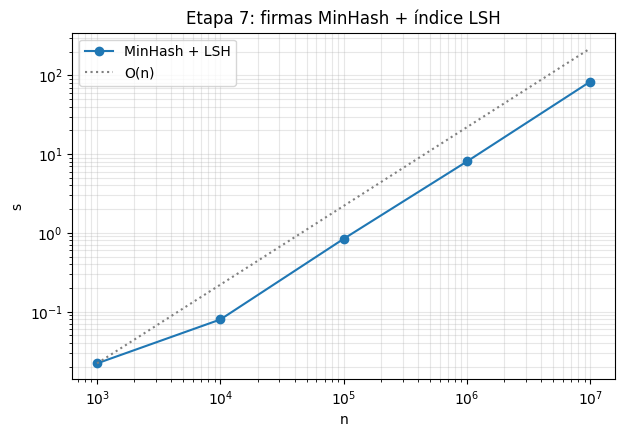

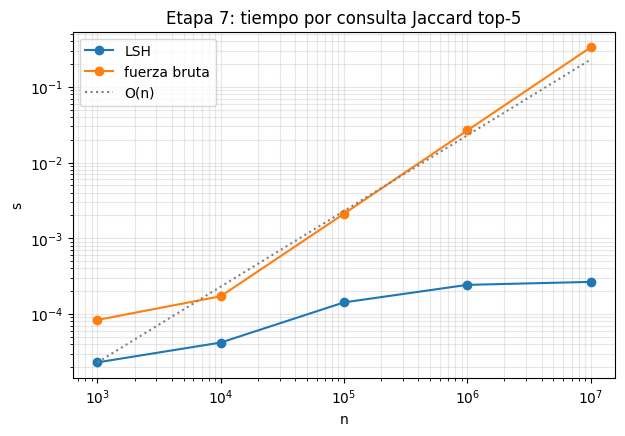

In [38]:
graficar_loglog(construccion_lsh, "Etapa 7: firmas MinHash + índice LSH", referencias=("n",))
graficar_loglog(consulta_lsh, "Etapa 7: tiempo por consulta Jaccard top-5", referencias=("n",))

### 7.3 HNSW vs KNN exacto
Productos sintéticos como en los scripts de Oscar: precio normalizado al azar y 100 categorías. M = 16,
ef_construcción = 100 y K = 5; se varía `ef` en la búsqueda. Recall@5 = fracción de los 5 vecinos exactos que
también devuelve HNSW. Construir el grafo en Python puro es lento (en 1M tarda ~18 min), así que se mide una sola vez
por tamaño, y la memoria pico solo hasta 10K. No se corre 10M: la construcción crece como n log n (94 s en 100K y
1,094 s en 1M), lo que en 10M serían unas 3.5 horas, y el grafo ocupa ~1.5 KB por producto (pico en 10K), unos
15 GB, casi toda la RAM del equipo (16 GB). Además, las 10M filas del dataset real tienen 121,903 productos, así
que 1M ya es ocho veces lo que el HNSW indexa en el pipeline.

In [39]:
TAMANOS_HNSW = [1_000, 10_000, 100_000, 1_000_000]
VALORES_EF = [50, 100, 200, 500]
CATEGORIAS_HNSW = [2103807459595380000 + i for i in range(100)]


def construir_hnsw(vectores):
    hnsw = HNSW(distancia_mixta, m=16, ef_construccion=100, seed=SEED)
    for pid, vector in vectores.items():
        hnsw.insertar(pid, vector)
    return hnsw


construccion_hnsw, consulta_hnsw = {}, {}
for n in TAMANOS_HNSW:
    rng = random.Random(SEED)
    vectores = {pid: (rng.random(), rng.choice(CATEGORIAS_HNSW)) for pid in range(1, n + 1)}
    hnsw, t_constr = cronometrar(lambda: construir_hnsw(vectores))
    pico = memoria_pico(lambda: construir_hnsw(vectores)) if n <= 10_000 else None
    puntos, ids = list(vectores.values()), list(vectores)
    consultas = rng.sample(ids, CONSULTAS_E7)

    exactos, t_exacto = {}, []
    for pid in consultas:
        vecinos, t = cronometrar(lambda: knn_exacto(puntos, ids, vectores[pid], K_E7 + 1))
        exactos[pid] = {p for _, p in vecinos if p != pid}
        t_exacto.append(t)
    construccion_hnsw.setdefault("HNSW", {})[n] = t_constr
    consulta_hnsw.setdefault("KNN exacto", {})[n] = statistics.mean(t_exacto)
    pico_txt = f"{pico / 1e6:6.2f} MB" if pico is not None else "—"
    print(f"n={n:>9,}  construcción {t_constr:7.2f} s  pico {pico_txt}  nivel máximo {hnsw.nivel_maximo}  "
          f"KNN exacto {statistics.mean(t_exacto) * 1e3:.3f} ± {statistics.stdev(t_exacto) * 1e3:.3f} ms")
    for ef in VALORES_EF:
        tiempos, recalls, nodos = [], [], []
        for pid in consultas:
            vecinos, t = cronometrar(lambda: hnsw.buscar(vectores[pid], K_E7 + 1, ef=ef))
            aproximados = [p for _, p in vecinos if p != pid][:K_E7]
            tiempos.append(t)
            recalls.append(len(set(aproximados) & exactos[pid]) / K_E7)
            nodos.append(hnsw.nodos_visitados)
        consulta_hnsw.setdefault(f"HNSW ef={ef}", {})[n] = statistics.mean(tiempos)
        print(f"    ef={ef:>3}  {statistics.mean(tiempos) * 1e3:7.3f} ± {statistics.stdev(tiempos) * 1e3:6.3f} ms  "
              f"recall@5 {statistics.mean(recalls):.3f}  nodos visitados (mediana) {statistics.median(nodos):,.0f}")

n=    1,000  construcción    0.58 s  pico   1.45 MB  nivel máximo 2  KNN exacto 0.311 ± 0.006 ms
    ef= 50    0.197 ±  0.027 ms  recall@5 0.752  nodos visitados (mediana) 269
    ef=100    0.353 ±  0.022 ms  recall@5 0.752  nodos visitados (mediana) 416
    ef=200    0.621 ±  0.053 ms  recall@5 0.794  nodos visitados (mediana) 570


    ef=500    1.223 ±  0.069 ms  recall@5 0.938  nodos visitados (mediana) 776


n=   10,000  construcción    8.62 s  pico  14.59 MB  nivel máximo 3  KNN exacto 3.814 ± 0.156 ms
    ef= 50    0.263 ±  0.047 ms  recall@5 0.688  nodos visitados (mediana) 286
    ef=100    0.456 ±  0.047 ms  recall@5 0.694  nodos visitados (mediana) 560
    ef=200    0.871 ±  0.078 ms  recall@5 0.728  nodos visitados (mediana) 918


    ef=500    1.810 ±  0.186 ms  recall@5 0.922  nodos visitados (mediana) 1,464


n=  100,000  construcción  102.38 s  pico —  nivel máximo 6  KNN exacto 61.131 ± 2.776 ms
    ef= 50    0.390 ±  0.133 ms  recall@5 0.590  nodos visitados (mediana) 209
    ef=100    0.598 ±  0.134 ms  recall@5 0.598  nodos visitados (mediana) 374


...

    ef=500    2.942 ±  0.554 ms  recall@5 0.842  nodos visitados (mediana) 1,412


n=1,000,000  construcción 1103.05 s  pico —  nivel máximo 6  KNN exacto 992.953 ± 41.697 ms
    ef= 50    1.858 ±  0.846 ms  recall@5 0.644  nodos visitados (mediana) 197


    ef=100    1.554 ±  0.390 ms  recall@5 0.652  nodos visitados (mediana) 366


    ef=200    2.359 ±  0.997 ms  recall@5 0.682  nodos visitados (mediana) 716


    ef=500    4.231 ±  1.533 ms  recall@5 0.796  nodos visitados (mediana) 1,293


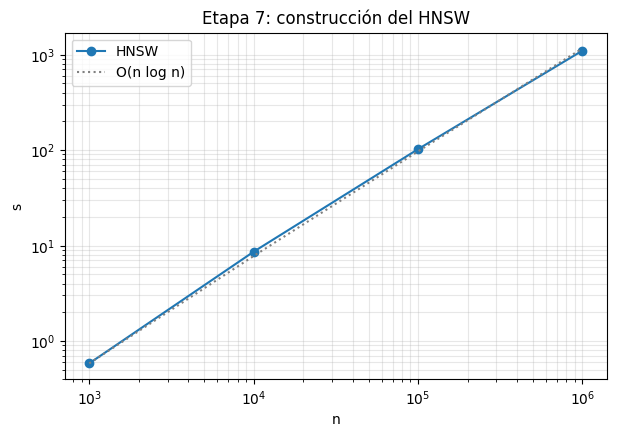

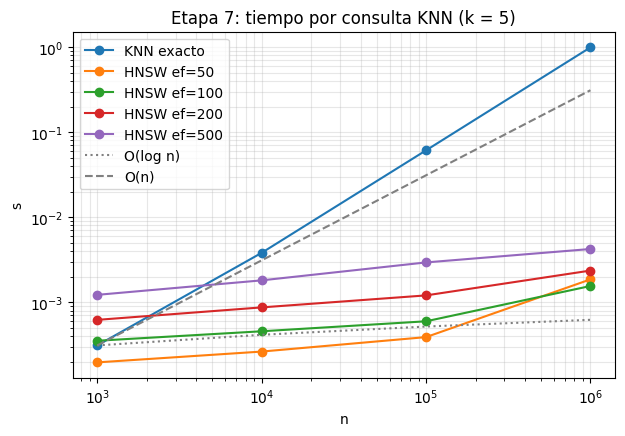

In [40]:
graficar_loglog(construccion_hnsw, "Etapa 7: construcción del HNSW", referencias=("n log n",))
graficar_loglog(consulta_hnsw, "Etapa 7: tiempo por consulta KNN (k = 5)", referencias=("log n", "n"))

### 7.4 Integración con datos reales
Las primeras 100K filas pasan por las etapas 0 → 1 → 2 y luego por las etapas 3 y 7, como en el despachador del
orquestador. Al cerrar, igual que en `Pipeline._cerrar`, se calculan las firmas y el KD-Tree se construye con el
catálogo de la etapa 3, y el HNSW recibe sus mismos vectores. En el recall contra el KD-Tree, un vecino cuenta
como acierto si su distancia no supera la del k-ésimo exacto: con datos reales hay muchos productos de la misma
categoría y el mismo precio, y entre ellos cualquiera es un vecino correcto.

Con 32 bandas de 4 filas, LSH solo propone pares con Jaccard alto (umbral ≈ (1/32)^(1/4) ≈ 0.42). En los datos reales
la mayoría de los productos tiene un solo comprador, así que pocos productos tienen relacionados.

In [41]:
from pipeline_eda.etapa0_ingesta import Ingesta, leer_csv
from pipeline_eda.etapa1_preproceso import Preprocesador
from pipeline_eda.etapa2_prioridad import ColaPrioridad
from pipeline_eda.etapa3_cache import CatalogoCache
from pipeline_eda.etapa5_kdtree import IndiceKD

e0, e1, e2, e3 = Ingesta(50_000, 10_000), Preprocesador(100_000), ColaPrioridad(), CatalogoCache(10_000)
e5, e7 = IndiceKD(), Similitud(distancia_mixta, seed=SEED)
for lote in e0.lotes(leer_csv(CSV_REAL, limite=100_000)):
    for ev in e1.procesar(lote):
        e2.push_evento(ev)
    while len(e2):
        ev = e2.pop()
        e3.consumir(ev)
        e7.consumir(ev)

e7.cerrar()
e5.construir(e3.productos())
vectores = dict(zip(e5.ids, e5.puntos))
_, t_constr = cronometrar(lambda: e7.construir_vectorial(vectores))

con_relacionados = [p for p in e7.conjuntos if e7.relacionados(p, 5)]
ejemplo = max(con_relacionados, key=lambda p: len(e7.conjuntos[p]))
print(f"MinHash + LSH: {len(con_relacionados):,} de {len(e7.conjuntos):,} productos con carrito o compra tienen "
      f"relacionados; p. ej. {ejemplo} ({len(e7.conjuntos[ejemplo])} usuarios) -> {e7.relacionados(ejemplo, 5)}")

rng = random.Random(SEED)
consultas = rng.sample(e5.ids, 100)
for ef in (50, 500):
    recalls = []
    for pid in consultas:
        exactos = [d for d, p in e5.arbol.knn(vectores[pid], 11) if p != pid][:10]
        aproximados = [d for d, p in e7.hnsw.buscar(vectores[pid], 11, ef=ef) if p != pid][:10]
        recalls.append(sum(d <= exactos[-1] for d in aproximados) / len(exactos))
    print(f"HNSW sobre {len(vectores):,} productos (construcción {t_constr:.1f} s), ef={ef}: "
          f"recall@10 contra el KD-Tree {statistics.mean(recalls):.3f}")
e7.metricas()

MinHash + LSH: 156 de 919 productos con carrito o compra tienen relacionados; p. ej. 1004237 (8 usuarios) -> [1004241]


HNSW sobre 20,561 productos (construcción 28.5 s), ef=50: recall@10 contra el KD-Tree 0.701


HNSW sobre 20,561 productos (construcción 28.5 s), ef=500: recall@10 contra el KD-Tree 0.715


{'productos_lsh': 919,
 'buckets_lsh': 27144,
 'productos_hnsw': 20561,
 'nivel_maximo_hnsw': 4,
 'nodos_visitados_ultima_consulta': 2525}

## Etapa 8 [FIJA] — PageRank y comunidades

El grafo de co-compra une dos productos con una arista cuyo peso es en cuántas órdenes se compraron juntos; cada
orden es una sesión (`order_id` de la etapa 0). PageRank mide la influencia de cada producto y se compara con el
ranking por grado ponderado. Label Propagation detecta comunidades y se compara con las componentes conexas.
`networkx` solo se usa como referencia para verificar PageRank y la modularidad.

### 8.1 Correctitud

In [4]:
import networkx as nx
from datetime import datetime, timezone

from pipeline_eda.etapa8_grafo import GrafoCoCompra
from pipeline_eda.evento import Event

T0 = datetime(2019, 10, 1, tzinfo=timezone.utc)


def compra_en(orden, producto):
    return Event(T0, "purchase", producto, 1, None, None, 10.0, 1, orden, order_id=orden)


# Órdenes a mano: o1 = {1, 2, 3}, o2 = {1, 2} y o3 = {4}. El 1 repetido en o1 no suma; el 4 se compró solo.
g = GrafoCoCompra(seed=SEED)
for orden, producto in [("o1", 1), ("o1", 2), ("o1", 1), ("o1", 3), ("o2", 1), ("o2", 2), ("o3", 4)]:
    g.consumir(compra_en(orden, producto))
g.consumir(Event(T0, "view", 5, 1, None, None, 10.0, 1, "o1"))  # las vistas no cuentan
assert g.adyacencia == {1: {2: 2, 3: 1}, 2: {1: 2, 3: 1}, 3: {1: 1, 2: 1}}

# PageRank y modularidad contra networkx en un grafo al azar
rng = random.Random(SEED)
g = GrafoCoCompra(seed=SEED)
for o in range(2_000):
    for p in rng.sample(range(500), rng.choice((2, 3, 4))):
        g.consumir(compra_en(f"o{o}", p))
G = nx.Graph()
for u, vecinos in g.adyacencia.items():
    for v, w in vecinos.items():
        G.add_edge(u, v, weight=w)
pr, pr_nx = g.pagerank(tol=1e-12), nx.pagerank(G, alpha=0.85, weight="weight", tol=1e-12)
assert abs(sum(pr.values()) - 1) < 1e-9 and max(abs(pr[u] - pr_nx[u]) for u in pr) < 1e-9


def grupos(particion):
    """Comunidades como listas ordenadas de productos."""
    por_comunidad = {}
    for u, c in particion.items():
        por_comunidad.setdefault(c, []).append(u)
    return sorted(sorted(us) for us in por_comunidad.values())


particion = g.comunidades()
assert abs(g.modularidad(particion) - nx.community.modularity(G, grupos(particion), weight="weight")) < 1e-9
print(f"PageRank == networkx ({g.iteraciones['pagerank']} iteraciones); modularidad == networkx")

PageRank == networkx (23 iteraciones); modularidad == networkx


In [5]:
# Dos grupos de 4 productos que se compran juntos 3 veces, unidos por una sola orden con los productos 4 y 5
g = GrafoCoCompra(seed=SEED)
for i, grupo in enumerate(([1, 2, 3, 4], [5, 6, 7, 8])):
    for vez in range(3):
        for p in grupo:
            g.consumir(compra_en(f"g{i}-{vez}", p))
for p in (4, 5):
    g.consumir(compra_en("puente", p))

lp, cc = g.comunidades(), g.comunidades("componentes")
print(f"Label Propagation:   {grupos(lp)}  Q = {g.modularidad(lp):.3f}")
print(f"Componentes conexas: {grupos(cc)}  Q = {g.modularidad(cc):.3f}")
assert grupos(lp) == [[1, 2, 3, 4], [5, 6, 7, 8]] and grupos(cc) == [[1, 2, 3, 4, 5, 6, 7, 8]]
g.metricas()

Label Propagation:   [[1, 2, 3, 4], [5, 6, 7, 8]]  Q = 0.473
Componentes conexas: [[1, 2, 3, 4, 5, 6, 7, 8]]  Q = 0.000


{'ordenes': 7,
 'nodos': 8,
 'aristas': 13,
 'comunidades': 2,
 'tamanos_mayores': [4, 4],
 'modularidad': 0.473,
 'iteraciones': {'label_propagation': 2}}

### 8.2 Con datos reales: PageRank vs ranking por grado
Las 10M filas pasan por las etapas 0 → 1 → 2 → 6 → 8 como en el orquestador, así que las compras bloqueadas por
fraude no llegan al grafo. Tiempo con 100 repeticiones; luego, solapamiento del top-K y correlación de Spearman entre
los dos puntajes, sobre todos los productos del grafo. En un grafo no dirigido, la distribución estacionaria de la
caminata aleatoria (PageRank sin el salto al azar) es proporcional al grado ponderado: se espera que coincidan arriba
del ranking. Más abajo hay muchos empates por grado, que PageRank desempata según la importancia de los vecinos.

In [6]:
from pipeline_eda.etapa0_ingesta import Ingesta, leer_csv
from pipeline_eda.etapa1_preproceso import Preprocesador
from pipeline_eda.etapa2_prioridad import ColaPrioridad
from pipeline_eda.etapa6_probabilistico import DetectorFraude
from pipeline_eda.evento import Alerta

e0, e1, e2 = Ingesta(50_000, 10_000), Preprocesador(100_000), ColaPrioridad()
e6, e8 = DetectorFraude(seed=SEED), GrafoCoCompra(seed=SEED)
e6.cargar_senalados(e0.senalados())
for lote in e0.lotes(leer_csv(CSV_REAL)):
    for ev in e1.procesar(lote):
        e2.push_evento(ev)
    while len(e2):
        item = e2.pop()
        if isinstance(item, Alerta):
            if not e6.verificar(item):  # falso positivo del Bloom: la compra se libera
                e8.consumir(item.evento)
            continue
        alerta = e6.consumir(item)
        if alerta is not None:
            e2.push_alerta(alerta)
        else:
            e8.consumir(item)

t_pr, sd_pr = medir(e8.pagerank, 100)
t_grado, sd_grado = medir(e8.ranking_por_grado, 100)
pr, ranking = e8.pagerank(), e8.ranking_por_grado()
grado = dict(ranking)
print(f"{len(e8._ordenes):,} órdenes, {len(e8.adyacencia):,} productos con aristas; "
      f"grado ponderado 1 o 2: {sum(g <= 2 for g in grado.values()) / len(grado):.2f} de los productos")
print(f"PageRank {t_pr * 1e3:.1f} ms ± {sd_pr * 1e3:.1f} ({e8.iteraciones['pagerank']} iteraciones)  "
      f"ranking por grado {t_grado * 1e3:.1f} ms ± {sd_grado * 1e3:.1f}  (100 reps)")
top_pr, top_grado = sorted(pr, key=lambda u: (-pr[u], u)), [u for u, _ in ranking]
for k in (10, 100, 1_000):
    print(f"top-{k:<5} {len(set(top_pr[:k]) & set(top_grado[:k])) / k:.2f} en común")
nodos = list(pr)
print(f"Spearman entre PageRank y grado: "
      f"{statistics.correlation([pr[u] for u in nodos], [grado[u] for u in nodos], method='ranked'):.3f}")

146,162 órdenes, 6,894 productos con aristas; grado ponderado 1 o 2: 0.66 de los productos
PageRank 371.1 ms ± 52.6 (64 iteraciones)  ranking por grado 3.6 ms ± 0.3  (100 reps)
top-10    1.00 en común
top-100   0.89 en común
top-1000  0.73 en común
Spearman entre PageRank y grado: 0.431


### 8.3 Comunidades: Label Propagation vs componentes conexas
Sobre el mismo grafo real: modularidad, tiempo (100 repeticiones), número y tamaños de las comunidades, y estabilidad.
Label Propagation depende del orden al azar en que visita los nodos: se corre con 10 seeds y cada partición se
compara con la del pipeline (seed 42) con NMI de `sklearn` (1 = idénticas). Las componentes conexas son
deterministas. Label Propagation tiende a formar una comunidad gigante alrededor de los productos más conectados.

In [7]:
from sklearn.metrics import normalized_mutual_info_score

for nombre, metodo in (("Label Propagation", "label_propagation"), ("componentes conexas", "componentes")):
    t, sd = medir(lambda: e8.comunidades(metodo), 100)
    particion = e8.comunidades(metodo)
    tamanos = sorted((len(us) for us in grupos(particion)), reverse=True)
    print(f"{nombre:<20} {t * 1e3:7.2f} ms ± {sd * 1e3:5.2f}  Q = {e8.modularidad(particion):.3f}  "
          f"{len(tamanos):,} comunidades, las 5 mayores {tamanos[:5]}, de 2 productos {sum(t == 2 for t in tamanos):,}")

base = e8.comunidades()
nmis, qs = [], []
for seed in range(10):
    particion = e8.comunidades(seed=seed)
    nmis.append(normalized_mutual_info_score([base[u] for u in nodos], [particion[u] for u in nodos]))
    qs.append(e8.modularidad(particion))
print(f"Label Propagation con 10 seeds: NMI {statistics.mean(nmis):.3f} ± {statistics.stdev(nmis):.3f} "
      f"(mínimo {min(nmis):.3f}), Q {statistics.mean(qs):.3f} ± {statistics.stdev(qs):.3f}")
e8.metricas()

Label Propagation     125.85 ms ± 33.53  Q = 0.357  1,572 comunidades, las 5 mayores [2467, 29, 20, 17, 17], de 2 productos 1,006


componentes conexas     3.52 ms ±  0.78  Q = 0.156  954 comunidades, las 5 mayores [4654, 10, 9, 9, 7], de 2 productos 733


Label Propagation con 10 seeds: NMI 0.938 ± 0.013 (mínimo 0.920), Q 0.406 ± 0.058


{'ordenes': 146162,
 'nodos': 6894,
 'aristas': 14053,
 'comunidades': 1572,
 'tamanos_mayores': [2467, 29, 20, 17, 17],
 'modularidad': 0.357,
 'iteraciones': {'pagerank': 64, 'label_propagation': 15}}

### 8.4 Escalabilidad con grafos sintéticos
El dataset real tiene ~146K órdenes, casi todas de un solo producto, así que la escala se mide con n órdenes
sintéticas de 2 a 4 productos, sobre n/2 productos con popularidad de Zipf (exponente 0.8): pocos productos muy
comprados y muchos poco comprados. El tiempo de construcción incluye generar los eventos. Complejidad esperada,
con N productos y E aristas: grado y componentes O(N + E); Label Propagation O(E) por vuelta y PageRank O(E) por
iteración. No se corre 10M: el grafo crece de forma lineal con las órdenes (en 1M tiene 430K productos, 2.4M aristas y
una memoria pico de 629 MB), así que en 10M serían unos 4.3M productos, 24M aristas y más de 6 GB. En un equipo de 16 GB eso obliga
al sistema a usar swap, y la corrida no termina en un tiempo razonable (se probó y se detuvo después de 30 minutos).
Además, el grafo real de las 10M filas tiene solo 6,894 productos y 14,053 aristas.

In [8]:
import itertools

TAMANOS_E8 = [1_000, 10_000, 100_000, 1_000_000]
REPS_E8 = {1_000: 100, 10_000: 100, 100_000: 10, 1_000_000: 3}


def compras_sinteticas(n_ordenes):
    rng = random.Random(SEED)
    n_productos = max(100, n_ordenes // 2)
    pesos = list(itertools.accumulate(1 / (r + 1) ** 0.8 for r in range(n_productos)))
    for o in range(n_ordenes):
        orden = f"o{o}"
        for p in rng.choices(range(n_productos), cum_weights=pesos, k=rng.choice((2, 2, 2, 3, 3, 4))):
            yield compra_en(orden, p)


def construir_grafo(n_ordenes):
    g = GrafoCoCompra(seed=SEED)
    for ev in compras_sinteticas(n_ordenes):
        g.consumir(ev)
    return g


tiempos_e8 = {}
for n in TAMANOS_E8:
    reps = REPS_E8[n]
    t, sd = medir(lambda: construir_grafo(n), reps)
    pico = memoria_pico(lambda: construir_grafo(n))
    g = construir_grafo(n)
    resultados = {"construcción": (t, sd)}
    for nombre, fn in (("PageRank", g.pagerank), ("ranking por grado", g.ranking_por_grado),
                       ("Label Propagation", g.comunidades), ("componentes conexas", lambda: g.comunidades("componentes"))):
        resultados[nombre] = medir(fn, reps)
    print(f"n={n:>10,} órdenes  {len(g.adyacencia):>9,} productos  "
          f"{sum(len(v) for v in g.adyacencia.values()) // 2:>10,} aristas  pico {pico / 1e6:7.1f} MB  ({reps} reps)  "
          f"iteraciones {g.iteraciones}")
    for nombre, (t, sd) in resultados.items():
        tiempos_e8.setdefault(nombre, {})[n] = t
        print(f"    {nombre:<20} {t:9.4f} s ± {sd:.4f}")
    del g

n=     1,000 órdenes        459 productos       2,144 aristas  pico     0.5 MB  (100 reps)  iteraciones {'pagerank': 23, 'label_propagation': 5}
    construcción            0.0036 s ± 0.0001
    PageRank                0.0094 s ± 0.0001
    ranking por grado       0.0002 s ± 0.0000
    Label Propagation       0.0029 s ± 0.0000
    componentes conexas     0.0002 s ± 0.0000


n=    10,000 órdenes      4,397 productos      22,623 aristas  pico     5.7 MB  (100 reps)  iteraciones {'pagerank': 21, 'label_propagation': 5}
    construcción            0.0433 s ± 0.0113
    PageRank                0.1024 s ± 0.0058
    ranking por grado       0.0023 s ± 0.0001
    Label Propagation       0.0332 s ± 0.0009
    componentes conexas     0.0022 s ± 0.0001


n=   100,000 órdenes     43,448 productos     233,878 aristas  pico    61.3 MB  (10 reps)  iteraciones {'pagerank': 31, 'label_propagation': 6}
    construcción            0.4813 s ± 0.0245
    PageRank                2.4528 s ± 0.2169
    ranking por grado       0.0346 s ± 0.0023
    Label Propagation       0.6053 s ± 0.0072
    componentes conexas     0.0465 s ± 0.0029


n= 1,000,000 órdenes    429,837 productos   2,392,678 aristas  pico   628.8 MB  (3 reps)  iteraciones {'pagerank': 30, 'label_propagation': 8}
    construcción            6.6011 s ± 0.5297
    PageRank               51.7593 s ± 0.7640
    ranking por grado       0.5838 s ± 0.0131
    Label Propagation      14.8133 s ± 0.3486
    componentes conexas     0.9306 s ± 0.0109


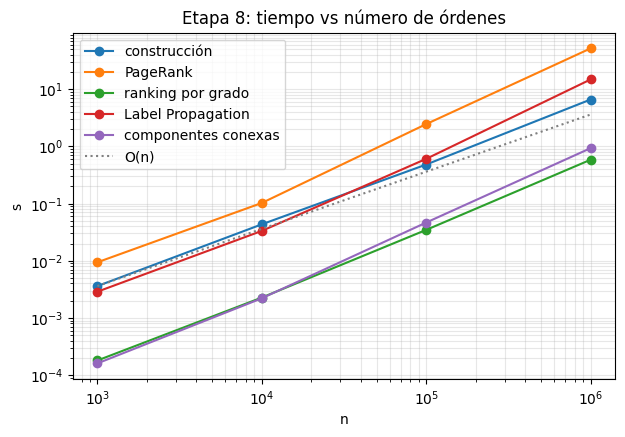

In [9]:
graficar_loglog(tiempos_e8, "Etapa 8: tiempo vs número de órdenes", referencias=("n",))

## Etapa 9 — Trie y Top-K *(pendiente)*

- `Trie` vs búsqueda de prefijo en lista ordenada + `bisect`.
- `TopK` vs `heapq.nlargest` y `sorted()[:k]`.